Notebook created in 2024 with the help of Xiaoyang Wei, Phd student at LIPADE, Université Paris Cité

# Interacting with CLIP

This is a self-contained notebook that shows how to download and run CLIP models, calculate the similarity between arbitrary image and text inputs, and perform zero-shot image classifications.

# Preparation for Colab

Make sure you're running a GPU runtime; if not, select "GPU" as the hardware accelerator in Runtime > Change Runtime Type in the menu. The next cells will install the `clip` package and its dependencies, and check if PyTorch 1.7.1 or later is installed.

In [1]:
! pip install ftfy regex tqdm
! pip install git+https://github.com/openai/CLIP.git

  Cloning https://github.com/openai/CLIP.git to /tmp/pip-req-build-ngx5h_hp
  Running command git clone --filter=blob:none --quiet https://github.com/openai/CLIP.git /tmp/pip-req-build-ngx5h_hp
  Resolved https://github.com/openai/CLIP.git to commit d05afc436d78f1c48dc0dbf8e5980a9d471f35f6
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for clip: filename=clip-1.0-py3-none-any.whl size=1369548 sha256=aa87b4fc0d80a1c0974d7a27597f6eb4c021a538395caa1463af5efd1788238a
  Stored in directory: /tmp/pip-ephem-wheel-cache-kz9h9po1/wheels/cb/a8/74/5f32d6cf0407457f0f62737b6da5c14eb86b9cac476fdf630d
Successfully built clip


> **Commentaire (sortie).** L'installation passe sans erreur : `ftfy` et `regex` servent au tokenizer BPE de CLIP, et le package `clip` est installé depuis le dépôt GitHub d'OpenAI. Le runtime Colab utilise Python 3.13 et une version récente de PyTorch, ce qui produira plus loin un simple avertissement (`torch.jit.load` déprécié) sans effet sur les résultats.

# Loading the model

`clip.available_models()` will list the names of available CLIP models.

In [2]:
import clip
import numpy as np

clip.available_models()

['RN50',
 'RN101',
 'RN50x4',
 'RN50x16',
 'RN50x64',
 'ViT-B/32',
 'ViT-B/16',
 'ViT-L/14',
 'ViT-L/14@336px']

> **Commentaire (sortie).** `clip.available_models()` liste 9 modèles, qui ne diffèrent que par l'encodeur d'image : 5 ResNet modifiés (RN50, RN101, puis RN50x4, x16 et x64, agrandis en largeur, profondeur et résolution) et 4 Vision Transformers (ViT-B/32, ViT-B/16, ViT-L/14 et ViT-L/14@336px, c'est-à-dire ViT-L/14 en entrée 336×336 pixels). Le chiffre après le « / » est la taille des patchs en pixels. Ces 9 modèles sont comparés en partie 2 du TP.

In [3]:
model, preprocess = clip.load("ViT-B/16")
model.cuda().eval()
input_resolution = model.visual.input_resolution
context_length = model.context_length
vocab_size = model.vocab_size

print("Model parameters:", f"{np.sum([int(np.prod(p.shape)) for p in model.parameters()]):,}")
print("Input resolution:", input_resolution)
print("Context length:", context_length)
print("Vocab size:", vocab_size)

100%|████████████████████████████████████████| 335M/335M [00:03<00:00, 115MiB/s]
/usr/local/lib/python3.13/dist-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


Model parameters: 149,620,737
Input resolution: 224
Context length: 77
Vocab size: 49408


> **Commentaire (sortie).** ViT-B/16 compte environ 149,6 M de paramètres (encodeur d'image et encodeur de texte réunis). Il attend des images de 224×224 pixels. Côté texte, la longueur de contexte est de 77 tokens et le vocabulaire BPE contient 49 408 entrées. Une légende plus longue que 77 tokens devra donc être tronquée, ce qui arrive souvent avec les légendes ROCO.

# Image Preprocessing

We resize the input images and center-crop them to conform with the image resolution that the model expects. Before doing so, we will normalize the pixel intensity using the dataset mean and standard deviation.

The second return value from `clip.load()` contains a torchvision `Transform` that performs this preprocessing.



In [4]:
preprocess

Compose(
    Resize(size=224, interpolation=bicubic, max_size=None, antialias=True)
    CenterCrop(size=(224, 224))
    <function _convert_image_to_rgb at 0x7afb313496c0>
    ToTensor()
    Normalize(mean=(0.48145466, 0.4578275, 0.40821073), std=(0.26862954, 0.26130258, 0.27577711))
)

> **Commentaire (sortie).** Le prétraitement redimensionne le petit côté à 224 pixels (interpolation bicubique), recadre au centre, convertit en RGB puis normalise avec la moyenne et l'écart-type propres à CLIP (et non ceux d'ImageNet). Le recadrage central peut couper des informations sur les bords des images médicales, qui sont souvent rectangulaires (radiographies du thorax, panoramiques dentaires).

# Text Preprocessing

We use a case-insensitive tokenizer, which can be invoked using `clip.tokenize()`. By default, the outputs are padded to become 77 tokens long, which is what the CLIP models expects.

In [5]:
clip.tokenize("Hello World!")

tensor([[49406,  3306,  1002,   256, 49407,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0]], dtype=torch.int32)

> **Commentaire (sortie).** « Hello World! » donne 5 tokens utiles : 49406 (début de texte), trois tokens pour *hello*, *world* et *!*, puis 49407 (fin de texte). Le reste est complété par des zéros jusqu'à 77. Le tokenizer met tout en minuscules, la casse des légendes n'a donc pas d'effet.

# Setting up input images and texts

We are going to feed 8 example natrural/medical images and their textual descriptions to the model, and compare the similarity between the corresponding features.

The tokenizer is case-insensitive, and we can freely give any suitable textual descriptions.

In [6]:
import os
import skimage
import IPython.display
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np
from collections import OrderedDict
import torch

%matplotlib inline
%config InlineBackend.figure_format = 'retina'

# Détection automatique de l'environnement (Kaggle, Colab ou Local)
if os.path.exists('/kaggle/working'):
    base_working_dir = '/kaggle/working'
elif os.getcwd() == '/content':
    try:
        from google.colab import drive
        drive.mount('/content/drive')
        base_working_dir = '/content/drive/MyDrive'
    except Exception:
        base_working_dir = os.getcwd()
else:
    base_working_dir = os.getcwd()

print(base_working_dir)

Mounted at /content/drive
/content/drive/MyDrive


In [7]:
import os

drive_path = '/content/drive/MyDrive/dataset_roco'

if os.path.exists(drive_path):
    print("✅ Le dossier 'dataset_roco' a bien été détecté dans votre Google Drive !")
    print("Contenu du dossier :", os.listdir(drive_path))
else:
    print("❌ Le dossier 'dataset_roco' est introuvable à l'adresse :", drive_path)
    print("Veuillez vérifier que le raccourci a bien été ajouté dans 'Mon Drive' et qu'il porte exactement ce nom.")

❌ Le dossier 'dataset_roco' est introuvable à l'adresse : /content/drive/MyDrive/dataset_roco
Veuillez vérifier que le raccourci a bien été ajouté dans 'Mon Drive' et qu'il porte exactement ce nom.


> **Commentaire (sortie).** Au premier essai, le dossier `dataset_roco` n'était pas trouvé : le raccourci vers le dossier partagé n'avait pas encore été ajouté dans « Mon Drive ». Après l'ajout du raccourci, la cellule de chemins plus bas (montage forcé du Drive) trouve bien les quatre chemins attendus.

### Update paths to point to the downloaded dataset
Now that the dataset is downloaded to `/content/dataset_roco`, we can map the image directories and CSV files to this local workspace path instead of depending on a custom Google Drive mount path.

In [8]:
# images to use and their textual descriptions
descriptions = {
    "page": "a page of text about segmentation",
    "chelsea": "a facial photo of a tabby cat",
    "astronaut": "a portrait of an astronaut with the American flag",
    "rocket": "a rocket standing on a launchpad",
    "motorcycle_right": "a red motorcycle standing in a garage",
    "camera": "a person looking at a camera on a tripod",
    "horse": "a black-and-white silhouette of a horse",
    "coffee": "a cup of coffee on a saucer"
}

med_descriptions = {
    "ROCO_00002": "CT scan in axial view showing obliteration of the left maxillary sinus",
    "ROCO_00017": "Coronary angiogram demonstrating occluded arteries",
    "ROCO_00028": "T2 weighted MRI image showing foraminal extensions of the cysts",
    "ROCO_00033": "Lytic lesions (arrows) involving the humerus.",
    "ROCO_00050": "Free air beneath the diaphragm at abdominal x-ray film",
    "ROCO_00056": "View of giant cell tumor of thumb metacarpal preoperatively",
    "ROCO_00060": "Transverse view of lung using CT.Leukemic infiltration is seen.",
    "ROCO_00135": "CT scan showing multiple non-communicating cysts in liver and kidney"
}

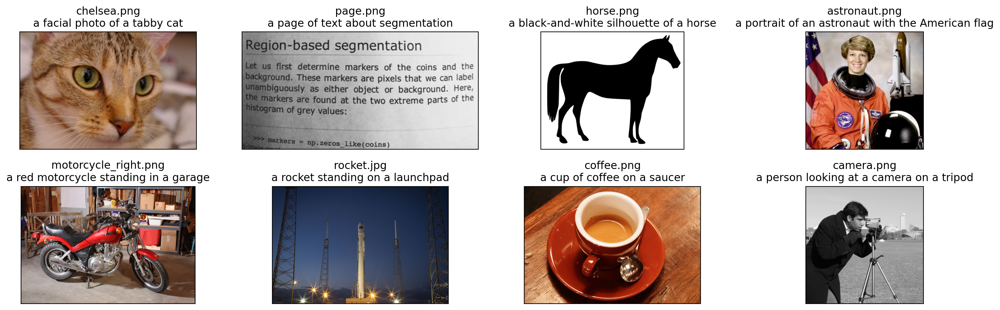

In [9]:
original_images = []
images = []
texts = []
plt.figure(figsize=(16, 5))

skimage.data.download_all(directory=None)
for filename in [filename for filename in os.listdir(skimage.data_dir) if filename.endswith(".png") or filename.endswith(".jpg")]:
    name = os.path.splitext(filename)[0]
    if name not in descriptions:
        continue

    image = Image.open(os.path.join(skimage.data_dir, filename)).convert("RGB")

    plt.subplot(2, 4, len(images) + 1)
    plt.imshow(image)
    plt.title(f"{filename}\n{descriptions[name]}")
    plt.xticks([])
    plt.yticks([])

    original_images.append(image)
    images.append(preprocess(image))
    texts.append(descriptions[name])

plt.tight_layout()


> **Commentaire (sortie).** Les 8 images naturelles de scikit-image s'affichent avec leur description. Le long journal de téléchargement vient de `skimage.data.download_all()`, qui récupère toutes les images d'exemple de la bibliothèque alors que seules 8 sont utilisées.

## Building features

We normalize the images, tokenize each text input, and run the forward pass of the model to get the image and text features.

In [10]:
image_input = torch.tensor(np.stack(images)).cuda()
text_tokens = clip.tokenize(["This is " + desc for desc in texts]).cuda()
with torch.no_grad():
    image_features = model.encode_image(image_input).float()
    text_features = model.encode_text(text_tokens).float()

## Calculating cosine similarity

We normalize the features and calculate the dot product of each pair.

Text(0.5, 1.0, 'Cosine similarity between text and image features(natural)')

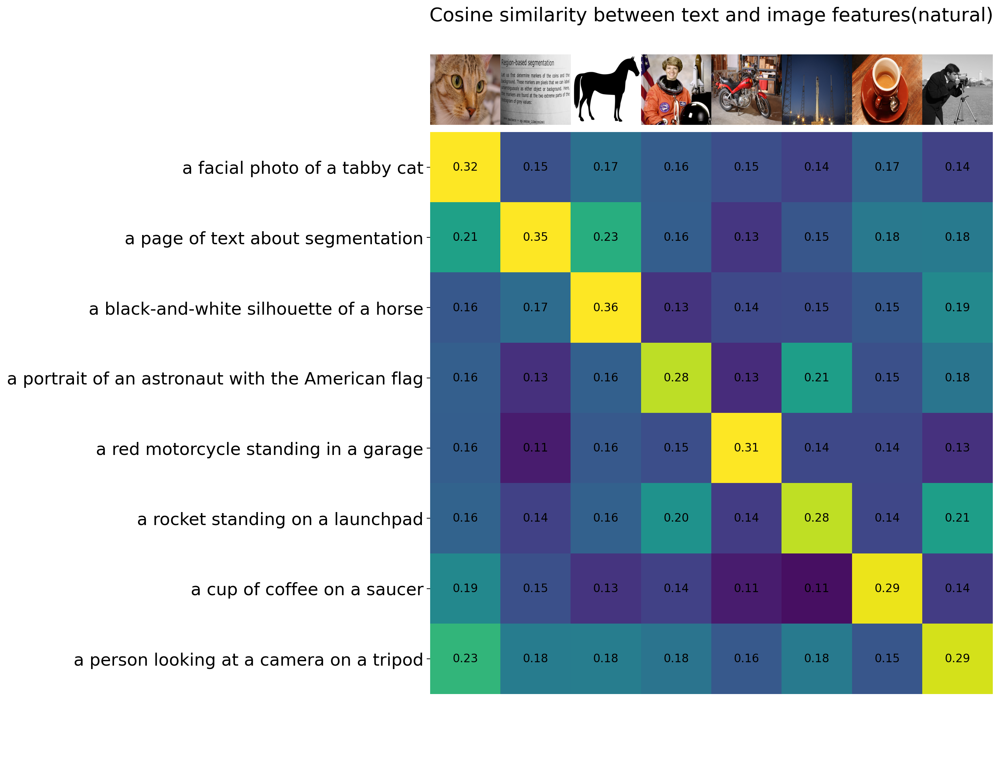

In [11]:
image_features /= image_features.norm(dim=-1, keepdim=True)
text_features /= text_features.norm(dim=-1, keepdim=True)
similarity = text_features.cpu().numpy() @ image_features.cpu().numpy().T

count = len(descriptions)

plt.figure(figsize=(20, 14))
plt.imshow(similarity, vmin=0.1, vmax=0.3)
# plt.colorbar()
plt.yticks(range(count), texts, fontsize=18)
plt.xticks([])
for i, image in enumerate(original_images):
    plt.imshow(image, extent=(i - 0.5, i + 0.5, -1.6, -0.6), origin="lower")
for x in range(similarity.shape[1]):
    for y in range(similarity.shape[0]):
        plt.text(x, y, f"{similarity[y, x]:.2f}", ha="center", va="center", size=12)

for side in ["left", "top", "right", "bottom"]:
  plt.gca().spines[side].set_visible(False)

plt.xlim([-0.5, count - 0.5])
plt.ylim([count + 0.5, -2])

plt.title("Cosine similarity between text and image features(natural)", size=20)

> **Commentaire (sortie).** Sur les images naturelles, la diagonale ressort nettement : chaque description a sa plus forte similarité avec la bonne image. La partie 1 du TP chiffre ce constat : 8 bonnes associations sur 8 dans les deux sens, une similarité moyenne de 0,31 pour les bonnes paires contre 0,16 pour les mauvaises. Les valeurs absolues restent faibles (autour de 0,3) ; c'est normal pour CLIP, seul l'ordre relatif des similarités compte pour la recherche et la classification.

In [13]:
import os
import pandas as pd

# --- 1) Montage du Google Drive dans Colab ---
from google.colab import drive
drive.mount('/content/drive',force_remount=True)

# --- 2) Chemins vers les données via le raccourci "dataset_roco" placé dans Mon Drive ---
DRIVE_FOLDER_NAME = "dataset_roco"
base_path = f"/content/drive/MyDrive/{DRIVE_FOLDER_NAME}/data"

csv_file     = os.path.join(base_path, "roco-list.csv")                             # paires d'entraînement
root_dir     = os.path.join(base_path, "pretrain_data/roco/train/radiology/images")  # images d'entraînement
val_csv_file = os.path.join(base_path, "local-val-list.csv")                        # paires de test
val_root_dir = os.path.join(base_path, "pretrain_data/roco/test/radiology/images")   # images de test

# --- 3) Vérifications : le raccourci existe et contient bien les fichiers attendus ---
assert os.path.exists(f"/content/drive/MyDrive/{DRIVE_FOLDER_NAME}"), \
    "Raccourci introuvable : l'ajouter dans 'Mon Drive' sous le nom 'dataset_roco'"

for chemin in [csv_file, root_dir, val_csv_file, val_root_dir]:
    print("✅" if os.path.exists(chemin) else "❌", chemin)

# Aperçu du CSV de test : nom de l'image et légende
val_df = pd.read_csv(val_csv_file)
print("\nPaires de test :", len(val_df))
print(val_df.head(3))


Mounted at /content/drive
✅ /content/drive/MyDrive/dataset_roco/data/roco-list.csv
✅ /content/drive/MyDrive/dataset_roco/data/pretrain_data/roco/train/radiology/images
✅ /content/drive/MyDrive/dataset_roco/data/local-val-list.csv
✅ /content/drive/MyDrive/dataset_roco/data/pretrain_data/roco/test/radiology/images

Paires de test : 8173
                A                                                  B
0  ROCO_00020.jpg  Axial computed tomography scan of the pelvis s...
1  ROCO_00027.jpg  Postoperative anteroposterior radiograph of th...
2  ROCO_00059.jpg  Angiography of the internal carotid artery, la...


> **Commentaire (sortie).** Après montage du Drive, les deux CSV et les deux dossiers d'images sont trouvés. Le fichier de validation `local-val-list.csv` contient 8 173 paires (nom de l'image, légende). Les légendes sont des phrases longues et techniques, très différentes des descriptions courtes des images naturelles.

## Performance of CLIP in medical domain

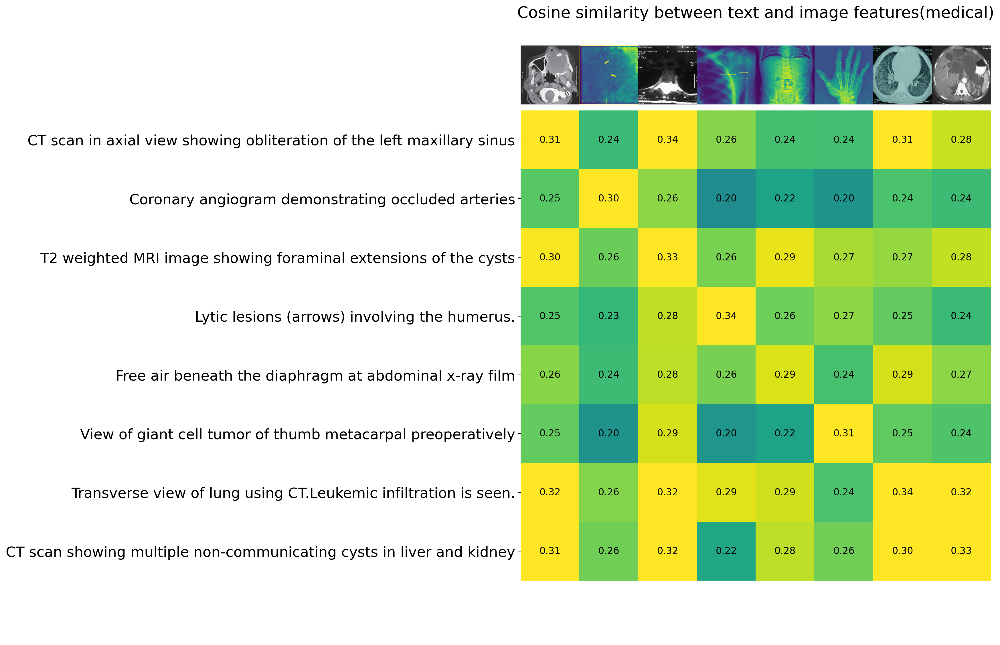

In [15]:
original_images = []
images = []
texts = []

# S'assurer que root_dir est bien défini et utilise la structure corrigée avec le dossier 'data'
root_dir = '/content/drive/MyDrive/dataset_roco/data/pretrain_data/roco/train/radiology/images'

for filename in list(med_descriptions.keys()):
    image_path = os.path.join(root_dir, filename + '.jpg')
    image = Image.open(image_path)
    original_images.append(image)
    images.append(preprocess(image))
    texts.append(med_descriptions[filename])

image_input = torch.tensor(np.stack(images)).cuda()
text_tokens = clip.tokenize(["This is " + desc for desc in texts]).cuda()
with torch.no_grad():
    image_features = model.encode_image(image_input).float()
    text_features = model.encode_text(text_tokens).float()
image_features /= image_features.norm(dim=-1, keepdim=True)
text_features /= text_features.norm(dim=-1, keepdim=True)
similarity = text_features.cpu().numpy() @ image_features.cpu().numpy().T

count = len(med_descriptions)

plt.figure(figsize=(20, 14))
plt.imshow(similarity, vmin=0.1, vmax=0.3)
plt.yticks(range(count), texts, fontsize=18)
plt.xticks([])
for i, image in enumerate(original_images):
    plt.imshow(image, extent=(i - 0.5, i + 0.5, -1.6, -0.6), origin="lower")
for x in range(similarity.shape[1]):
    for y in range(similarity.shape[0]):
        plt.text(x, y, f"{similarity[y, x]:.2f}", ha="center", va="center", size=12)
for side in ["left", "top", "right", "bottom"]:
  plt.gca().spines[side].set_visible(False)

plt.xlim([-0.5, count - 0.5])
plt.ylim([count + 0.5, -2])

plt.title("Cosine similarity between text and image features(medical)", size=20)
plt.show()

> **Commentaire (sortie).** Sur les 8 images ROCO, la heatmap est beaucoup plus uniforme : presque toutes les similarités sont entre 0,20 et 0,34. La partie 1 du TP mesure 7 bonnes associations sur 8 dans le sens texte → image mais seulement 5 sur 8 dans le sens image → texte, et un écart bonnes/mauvaises paires de 0,056 (contre 0,151 sur les images naturelles). On voit aussi que les légendes qui contiennent « CT » (lignes 1, 7 et 8) ont des similarités élevées (0,28 à 0,34) avec toutes les coupes, scanners comme IRM : CLIP semble reconnaître le type d'examen plus que la lésion décrite.

# Zero-Shot Image Classification

You can classify images using the cosine similarity (times 100) as the logits to the softmax operation.

In [17]:
from torchvision.datasets import CIFAR100
cifar100 = CIFAR100(root="/content/sample_data", transform=preprocess, download=True)

100%|██████████| 169M/169M [40:42<00:00, 69.2kB/s]


> **Commentaire (sortie).** Le téléchargement de CIFAR-100 (169 Mo) a pris environ 40 minutes à cause d'un débit très faible ce jour-là. Sans argument `train=False`, torchvision charge le split d'entraînement (50 000 images) ; ce n'est pas gênant ici puisqu'on ne réentraîne rien, mais il faut le savoir pour comparer avec les chiffres publiés, calculés sur le split de test.

In [18]:
text_descriptions = [f"This is a photo of a {label}" for label in cifar100.classes]
text_tokens = clip.tokenize(text_descriptions).cuda()

In [19]:
with torch.no_grad():
    text_features = model.encode_text(text_tokens).float()
    text_features /= text_features.norm(dim=-1, keepdim=True)

text_probs = (100.0 * image_features @ text_features.T).softmax(dim=-1)
top_probs, top_labels = text_probs.cpu().topk(5, dim=-1)

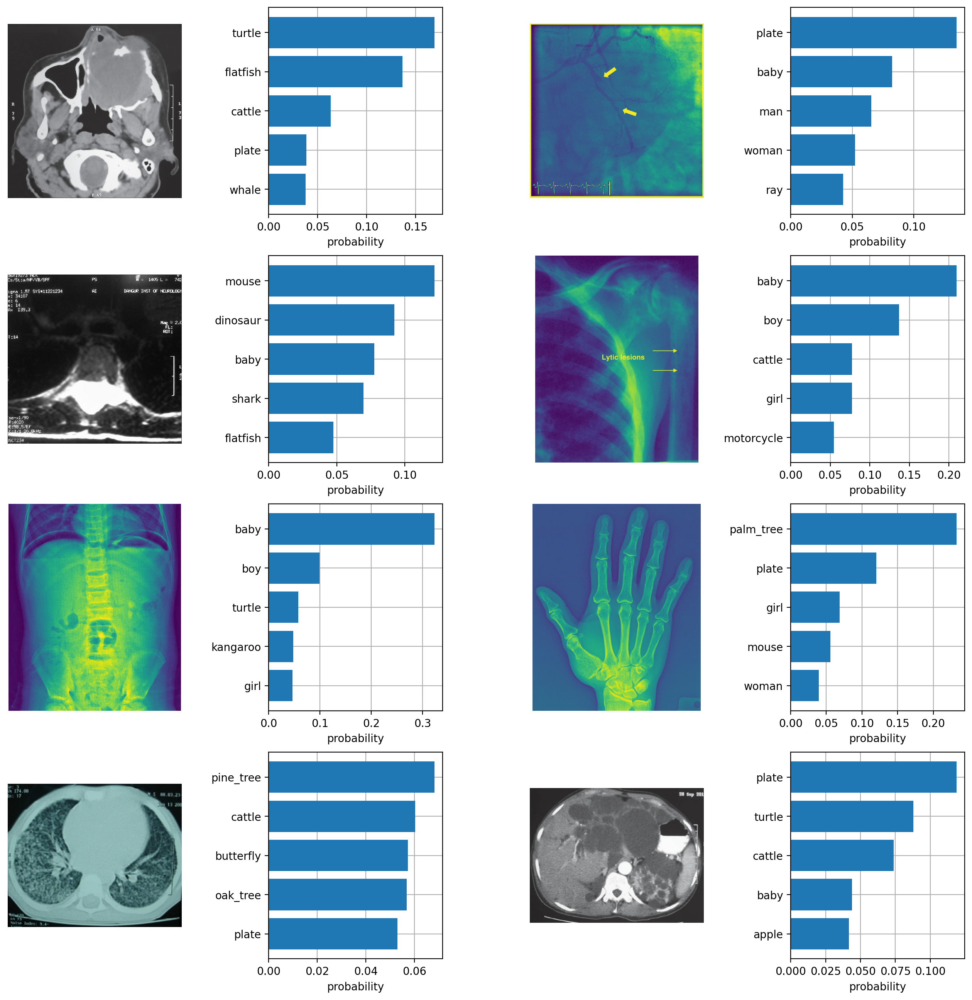

In [20]:
plt.figure(figsize=(16, 16))

for i, image in enumerate(original_images):
    plt.subplot(4, 4, 2 * i + 1)
    plt.imshow(image)
    plt.axis("off")

    plt.subplot(4, 4, 2 * i + 2)
    y = np.arange(top_probs.shape[-1])
    plt.grid()
    plt.barh(y, top_probs[i])
    plt.gca().invert_yaxis()
    plt.gca().set_axisbelow(True)
    plt.yticks(y, [cifar100.classes[index] for index in top_labels[i].numpy()])
    plt.xlabel("probability")

plt.subplots_adjust(wspace=0.5)
plt.show()

> **Commentaire (sortie).** Cette démo ne classe pas des images CIFAR : la variable `image_features` contient encore les embeddings des 8 images **médicales** calculés deux cellules plus haut. CLIP doit donc choisir pour une radiographie ou un scanner parmi les 100 classes de CIFAR-100, dont aucune ne convient. Il répond « turtle », « plate », « baby » ou « palm_tree » avec des probabilités faibles (souvent sous 0,2). La démo montre une limite du zero-shot : le softmax impose de choisir parmi les classes proposées, même quand aucune n'a de sens. La « vraie » classification zero-shot sur CIFAR-100 est faite en partie 2.

# Fine-tuning CLIP on ROCO



In [21]:
import os

# Après avoir créé un raccourci du dossier partagé dans votre "Mon Drive"
# Spécifiez le nom du raccourci ou dossier ici :
DRIVE_FOLDER_NAME = "dataset_roco"

# Ajusté pour pointer vers le sous-dossier 'data' présent dans le raccourci
base_path = f"/content/drive/MyDrive/{DRIVE_FOLDER_NAME}/data"

# dataset location
csv_file = os.path.join(base_path, "roco-list.csv")
root_dir = os.path.join(base_path, "pretrain_data/roco/train/radiology/images")
val_csv_file = os.path.join(base_path, "local-val-list.csv")
val_root_dir = os.path.join(base_path, "pretrain_data/roco/val/radiology/images")
# train options
seed = 42
batch_size = 16
image_size = 224
start_epoch = 0
epochs = 2
visual_encoder = "clip@ViT-B/16"
learning_rate = 3e-6
model_path = "/content/drive/My Drive/model_checkpoint_CLIP_ROCO"


In [22]:
import os
import numpy as np
import pandas as pd
import torch
import torchvision
import datetime
import time
from tqdm import tqdm
from PIL import Image, ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True
from torch.utils.data import Dataset
import random
import clip



class CLRDataset(Dataset):
    """Contrastive Learning Representations Dataset."""

    def __init__(self, csv_file, root_dir, transform=None, clip=False):
        self.clr_frame = pd.read_csv(csv_file)
        self.root_dir = root_dir
        self.transform = transform
        self.clip = clip

    def __len__(self):
        return len(self.clr_frame)

    def text_sampling(self, text):
        text = text.replace("\n", " ")
        text = text.split(".")
        if '' in text:
            text.remove('')
        text = random.choice(text)
        return text

    def __getitem__(self, idx):
        if torch.is_tensor(idx):
            idx = idx.tolist()

        img_name = os.path.join(self.root_dir,
                                self.clr_frame.iloc[idx, 0]
                                )
        if not os.path.exists(img_name):
            img_name=img_name.replace('train','val')
        image = Image.open(img_name)
        if not self.clip:
            image = image.convert('RGB')
        text = self.clr_frame.iloc[idx, 1]
        name = self.clr_frame.iloc[idx, 0]
        sample = {'image': image, 'text': text,'name':name}
        if self.clip:
            sample = self.transform(sample['image']), sample['text'],sample['name'] #self.text_sampling(sample['text'])
        elif self.transform:
            sample = self.transform(sample)

        return sample


def load_optimizer( model, lr=3e-6):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, epochs, eta_min=0, last_epoch=-1
    )
    return optimizer, scheduler


def train( train_loader, model, tokenizer, optimizer,truncation):
    loss_epoch = 0
    for step, (images, texts,name) in enumerate(train_loader):
        optimizer.zero_grad()
        x_v = images.to('cuda')
        x_u = tokenizer(list(texts), truncate=True).to('cuda')

        v,u=model(x_v,x_u)

        labels = torch.arange(batch_size, dtype=torch.long, device='cuda')

        loss_img = torch.nn.CrossEntropyLoss()
        loss_txt = torch.nn.CrossEntropyLoss()

        img_loss = loss_img(v,labels)
        text_loss = loss_txt(u,labels)

        loss = (img_loss + text_loss)/2

        loss.backward()
        optimizer.step()

        if step % 500 == 0:
            print(f"Step [{step}/{len(train_loader)}]\t Loss: {loss.item()}")

        loss_epoch += loss.item()
    return loss_epoch



def validate( val_loader, model, tokenizer, optimizer, truncation):

    with torch.no_grad():
        model.eval()
        loss_epoch = 0
        for step, (x_v, x_u, _) in enumerate(val_loader):
            x_v = x_v.to('cuda')
            x_u = tokenizer(list(x_u), truncate=True).to('cuda')

            v,u=model(x_v,x_u)

            labels = torch.arange(batch_size, dtype=torch.long, device='cuda')

            loss_img = torch.nn.CrossEntropyLoss()
            loss_txt = torch.nn.CrossEntropyLoss()

            img_loss = loss_img(v,labels)
            text_loss = loss_txt(u,labels)

            loss = (img_loss + text_loss)/2
            loss_epoch += loss.item()

    model.train()
    return loss_epoch


def main(gpu):

    is_master=True

    # set GPU device
    torch.cuda.set_device(gpu)
    torch.manual_seed(seed)
    np.random.seed(seed)

    # initialize model
    print("Initializing model... ", end="", flush=True)
    model, preprocess = clip.load(visual_encoder.split("@")[-1], device='cuda', jit=False)
    model.float()
    tokenizer=clip.tokenize
    train_fonction = train
    validate_fonction = validate

    # optimizer
    optimizer, scheduler = load_optimizer(model, lr=float(learning_rate))

    # initialize dataloader
    transform = preprocess
    print('Image_Transform',transform)
    train_dataset = CLRDataset(csv_file=csv_file,
                               root_dir=root_dir,
                               transform=transform,
                               clip = True
                               )

    val_dataset = CLRDataset(csv_file=val_csv_file,
                             root_dir=val_root_dir,
                             transform=transform,
                             clip = True
                             )

    train_sampler = None
    train_loader = torch.utils.data.DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=(train_sampler is None),
        drop_last=True,
        num_workers=8,
        sampler=train_sampler,
    )

    val_loader = torch.utils.data.DataLoader(
        val_dataset,
        batch_size=batch_size,
        drop_last=True,
        num_workers=8
    )

    print("[DONE]\n")
    print("STARTING TRAINING")
    print('Start Time =', datetime.datetime.now().strftime("%H:%M:%S"), '\n')

    t0 = time.time()
    global_step = 0
    current_epoch = 0
    best_val_loss = np.inf

    for epoch in range(0, epochs):
        if epoch<2:
            if train_sampler is not None:
                train_sampler.set_epoch(epoch)

            lr = optimizer.param_groups[0]["lr"]
            loss_epoch = train_fonction(train_loader, model, tokenizer, optimizer,True)

        if is_master:
            val_loader
            return
            val_loss = validate_fonction( val_loader, model, tokenizer, optimizer, True)
            if val_loss < best_val_loss:
                torch.save(model.state_dict(), os.path.join(model_path, "best_checkpoint.pth"))
                best_val_loss = val_loss

            epoch_counter = epoch - 0
            elapsed = time.time() - t0
            epoch_time = elapsed/(epoch_counter+1)
            remaining = (epochs - (epoch_counter+1))*epoch_time
            remaining = str(datetime.timedelta(seconds=round(remaining)))
            elapsed = str(datetime.timedelta(seconds=round(elapsed)))
            print(f'Epoch {epoch_counter+1}/{epochs} [{elapsed}<{remaining}, {round(epoch_time, 2)}s/epoch] {round((epoch_counter+1)/epochs*100, 1)}% loss: {loss_epoch / len(train_loader)}\t val_loss: {val_loss / len(val_loader)} lr: {lr}')

            current_epoch += 1


if not os.path.exists(model_path):
    os.makedirs(model_path)

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print("Device:", device)
main(0)

Device: cuda:0
Initializing model... 

/usr/local/lib/python3.13/dist-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


Image_Transform Compose(
    Resize(size=224, interpolation=bicubic, max_size=None, antialias=True)
    CenterCrop(size=(224, 224))
    <function _convert_image_to_rgb at 0x7afb313496c0>
    ToTensor()
    Normalize(mean=(0.48145466, 0.4578275, 0.40821073), std=(0.26862954, 0.26130258, 0.27577711))
)
[DONE]

STARTING TRAINING
Start Time = 22:57:17 



/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:431: UserWarning: This DataLoader will create 8 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:437: UserWarning: This DataLoader will create 8 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


Step [0/4087]	 Loss: 1.6037722826004028
Step [500/4087]	 Loss: 0.9935240745544434
Step [1000/4087]	 Loss: 0.9995275735855103
Step [1500/4087]	 Loss: 0.9409730434417725
Step [2000/4087]	 Loss: 0.7876063585281372
Step [2500/4087]	 Loss: 0.7014217376708984
Step [3000/4087]	 Loss: 0.4490070343017578
Step [3500/4087]	 Loss: 0.6463015079498291
Step [4000/4087]	 Loss: 0.3318662941455841


> **Commentaire (sortie).** Le fine-tuning de ViT-B/16 sur ROCO compte 4 087 itérations par époque (batch de 16, soit environ 65 000 paires). La loss contrastive passe de 1,60 à 0,33 sur la première époque, avec des oscillations (0,45 puis 0,65 puis 0,33) dues à la petite taille de batch. Pour comparaison, un modèle qui répond au hasard aurait une loss de ln(16) ≈ 2,77 : CLIP pré-entraîné aligne donc déjà en partie les paires médicales au départ.
>
> En lisant le code, on remarque un `return` placé avant la validation dans la boucle d'époques : l'entraînement s'arrête après la première époque et `best_checkpoint.pth` n'est jamais écrit. La suite du tutoriel, et la partie 3 du TP, utilisent donc le checkpoint fourni avec les données (`ViT-B-16_best_checkpoint_2.tar`) et non celui de cette exécution.

In [23]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Performance of CLIP in medical domain(after fine-tuning on ROCO )

Text(0.5, 1.0, 'Cosine similarity between text and image features(medical)')

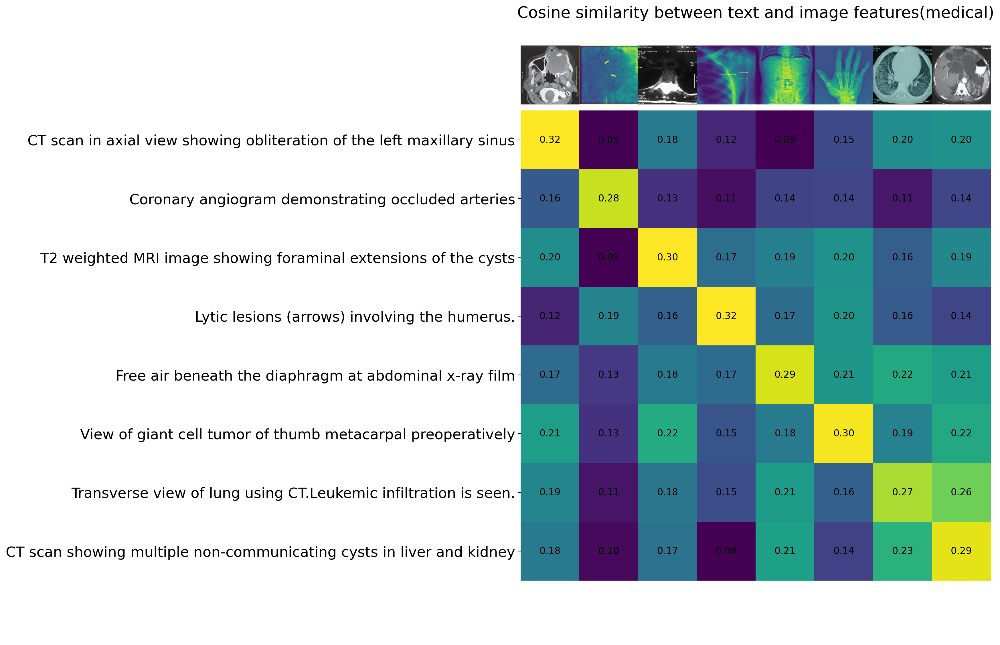

In [24]:
#load checkpoint
model.load_state_dict(torch.load('/content/drive/MyDrive/dataset_roco/data/ViT-B-16_best_checkpoint_2.tar'))

#compute txt-img similarity again
original_images = []
images = []
texts = []
for filename in list(med_descriptions.keys()):
    image = Image.open(os.path.join(root_dir, filename+'.jpg'))
    original_images.append(image)
    images.append(preprocess(image))
    texts.append(med_descriptions[filename])
image_input = torch.tensor(np.stack(images)).cuda()
text_tokens = clip.tokenize(["This is " + desc for desc in texts]).cuda()
with torch.no_grad():
    image_features = model.encode_image(image_input).float()
    text_features = model.encode_text(text_tokens).float()
image_features /= image_features.norm(dim=-1, keepdim=True)
text_features /= text_features.norm(dim=-1, keepdim=True)
similarity = text_features.cpu().numpy() @ image_features.cpu().numpy().T

count = len(descriptions)

plt.figure(figsize=(20, 14))
plt.imshow(similarity, vmin=0.1, vmax=0.3)
plt.yticks(range(count), texts, fontsize=18)
plt.xticks([])
for i, image in enumerate(original_images):
    plt.imshow(image, extent=(i - 0.5, i + 0.5, -1.6, -0.6), origin="lower")
for x in range(similarity.shape[1]):
    for y in range(similarity.shape[0]):
        plt.text(x, y, f"{similarity[y, x]:.2f}", ha="center", va="center", size=12)

for side in ["left", "top", "right", "bottom"]:
  plt.gca().spines[side].set_visible(False)

plt.xlim([-0.5, count - 0.5])
plt.ylim([count + 0.5, -2])

plt.title("Cosine similarity between text and image features(medical)", size=20)

> **Commentaire (sortie).** Avec le checkpoint fine-tuné, la diagonale ressort nettement : 8 bonnes associations sur 8 et des similarités hors diagonale qui descendent jusqu'à 0,05. Ce résultat est à prendre avec prudence, car ces 8 images viennent du dossier `train` de ROCO et ont donc été vues pendant le fine-tuning. Pour une évaluation honnête, la partie 3 du TP refait la mesure sur des images de validation.

---

# Partie TP : réponses aux consignes

*Tout ce qui précède est le tutoriel d'origine, laissé tel quel. Les cellules ci-dessous ont été ajoutées pour le TP.*

**M2 VMI — Multi-modalité et IA générative (IFLCE055)** · Lucka Harena

Cette partie s'appuie sur le tutoriel ci-dessus et répond aux quatre consignes du sujet :

| Partie | Consigne |
|---|---|
| 1 | Prise en main du code et des démos (similarité image/texte, zero-shot) |
| 2 | Comparaison quantitative des modèles CLIP disponibles |
| 3 | Résultats de CLIP dans le domaine médical sur d'autres exemples de ROCO |
| 4 | Classification zero-shot d'images naturelles sur un autre jeu que CIFAR-100 (Oxford-IIIT Pet) |

**Rappel du principe (cours 1, partie « Contrastive models »).** CLIP (Radford et al., 2021) apprend deux encodeurs, un pour l'image et un pour le texte, qui projettent leurs entrées dans un espace commun. L'entraînement utilise une loss contrastive symétrique sur 400 M paires image/texte du web : dans un batch de $N$ paires, la paire $(i, i)$ doit avoir une similarité cosinus plus grande que les $N-1$ paires $(i, j)$ incorrectes. Une fois entraîné, on peut classer une image *sans réentraînement* (zero-shot) en comparant son embedding à ceux de phrases du type « a photo of a {classe} ».

**Exécution.** Cette partie est indépendante des cellules du tutoriel : elle recharge ses imports, ses modèles et ses chemins (mêmes chemins Drive que le tutoriel). Il n'est donc pas nécessaire de relancer le fine-tuning du tutoriel, qui prend plusieurs heures : cliquer sur la cellule « 0. Installation » ci-dessous puis *Exécution > Exécuter les cellules suivantes*, avec un runtime GPU.

Toutes les métriques sont enregistrées dans `resultats_tp_clip.json` et les figures dans le dossier `TP_CLIP_resultats/` du Google Drive, pour le rapport.

## 0. Installation et configuration

In [ ]:
# Installation du package CLIP officiel d'OpenAI et de ses dépendances
!pip install -q ftfy regex tqdm
!pip install -q git+https://github.com/openai/CLIP.git

In [31]:
import os, re, json, time, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image, ImageFile
import clip

ImageFile.LOAD_TRUNCATED_IMAGES = True   # certaines images ROCO sont tronquées

# --- Reproductibilité : on fixe toutes les graines aléatoires ---
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device :", device)
if device == "cpu":
    print("ATTENTION : pas de GPU, l'évaluation des 9 modèles sera très lente.")

# --- Montage du Google Drive (données ROCO + sauvegarde des résultats) ---
from google.colab import drive
drive.mount('/content/drive')

DRIVE_FOLDER_NAME = "dataset_roco"                          # nom du raccourci dans "Mon Drive"
BASE_PATH = f"/content/drive/MyDrive/{DRIVE_FOLDER_NAME}/data"
ROCO_TRAIN_DIR = os.path.join(BASE_PATH, "pretrain_data/roco/train/radiology/images")
ROCO_TEST_DIR  = os.path.join(BASE_PATH, "pretrain_data/roco/val/radiology/images")
ROCO_TEST_CSV  = os.path.join(BASE_PATH, "local-val-list.csv")   # paires (image, légende) du jeu de test

RESULTS_DIR = "/content/drive/MyDrive/TP_CLIP_resultats"   # résultats et figures pour le rapport
os.makedirs(RESULTS_DIR, exist_ok=True)

# --- Paramètres des expériences (réduire si le temps Colab manque) ---
BATCH_SIZE  = 64      # taille de batch pour l'inférence
NUM_WORKERS = 2       # Colab recommande 2 workers
N_ROCO_RETRIEVAL = 1000   # nombre de paires ROCO de test pour la recherche image <-> texte

# Dictionnaire qui accumule toutes les métriques, sauvegardé en JSON à la fin de chaque partie
results = {"config": {"seed": SEED, "batch_size": BATCH_SIZE,
                      "n_roco_retrieval": N_ROCO_RETRIEVAL,
                      "gpu": torch.cuda.get_device_name(0) if device == "cuda" else "cpu"}}

def save_results():
    with open(os.path.join(RESULTS_DIR, "resultats_tp_clip.json"), "w") as f:
        json.dump(results, f, indent=2, ensure_ascii=False, default=float)
    print("Résultats sauvegardés dans", RESULTS_DIR)

def save_fig(name):
    plt.savefig(os.path.join(RESULTS_DIR, name), dpi=200, bbox_inches="tight")

print("Dossier ROCO trouvé :", os.path.exists(BASE_PATH))

Device : cuda
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dossier ROCO trouvé : True


## Fonctions utilitaires communes

On regroupe ici les opérations répétées dans toutes les parties, pour que le code des expériences reste court :

- `encode_images` / `encode_texts` : passent les données dans l'encodeur image ou texte de CLIP, puis **normalisent** les embeddings ($\|x\|_2 = 1$). Le produit scalaire entre deux vecteurs normalisés est alors leur **similarité cosinus**, comme dans le notebook d'origine.
- `zero_shot_classifier` : construit un « classifieur » à partir des noms de classes, sans aucun apprentissage. Chaque classe devient le vecteur texte de sa phrase-prompt.
- `recall_at_k` : métrique standard de recherche image ↔ texte (cours, partie « Evaluation », tâche *image-caption retrieval* de COCO).

In [32]:
@torch.no_grad()
def encode_images(model, loader):
    # Encode toutes les images d'un DataLoader.
    # Retourne (features normalisées [N, d], étiquettes [N], temps moyen par image en ms).
    feats, labels = [], []
    if device == "cuda": torch.cuda.synchronize()
    t0 = time.time()
    for images, y in loader:
        f = model.encode_image(images.to(device)).float()
        feats.append(f / f.norm(dim=-1, keepdim=True))   # normalisation L2
        labels.append(torch.as_tensor(y))
    if device == "cuda": torch.cuda.synchronize()
    n = sum(len(l) for l in labels)
    ms_per_img = 1000 * (time.time() - t0) / n
    return torch.cat(feats).cpu(), torch.cat(labels), ms_per_img


@torch.no_grad()
def encode_texts(model, texts, batch_size=256):
    # Tokenise puis encode une liste de phrases. truncate=True coupe à 77 tokens
    # (longueur de contexte maximale de CLIP), utile pour les longues légendes ROCO.
    feats = []
    for i in range(0, len(texts), batch_size):
        tokens = clip.tokenize(texts[i:i + batch_size], truncate=True).to(device)
        f = model.encode_text(tokens).float()
        feats.append(f / f.norm(dim=-1, keepdim=True))
    return torch.cat(feats).cpu()


def zero_shot_classifier(model, classnames, template):
    # Un vecteur texte par classe, obtenu avec le prompt `template` (ex : "a photo of a {}.").
    return encode_texts(model, [template.format(c) for c in classnames])


def topk_accuracy(img_feats, txt_feats, labels, ks=(1, 5)):
    # Comme dans le notebook : logits = 100 * similarité cosinus, puis on prend les k meilleures classes.
    logits = 100.0 * img_feats @ txt_feats.T
    topk = logits.topk(max(ks), dim=-1).indices
    correct = topk == labels.unsqueeze(1)
    return {f"top{k}": 100.0 * correct[:, :k].any(dim=1).float().mean().item() for k in ks}, topk[:, 0]


def mean_per_class_accuracy(preds, labels, n_classes):
    # Moyenne des précisions par classe (métrique utilisée par Radford et al. pour Oxford Pets).
    accs = [(preds[labels == c] == c).float().mean().item()
            for c in range(n_classes) if (labels == c).any()]
    return 100.0 * float(np.mean(accs))


def recall_at_k(sim, ks=(1, 5, 10)):
    # sim[i, j] = similarité entre la requête i et le candidat j ; la bonne réponse de i est j = i.
    # Rang de la bonne réponse = nombre de candidats strictement mieux classés.
    correct = sim.diag().unsqueeze(1)
    ranks = (sim > correct).sum(dim=1)
    return {f"R@{k}": 100.0 * (ranks < k).float().mean().item() for k in ks}


def count_params(model):
    return sum(p.numel() for p in model.parameters())

## 1. Prise en main du tutoriel (consigne 1)

Les deux démos de similarité ont été exécutées plus haut dans le tutoriel (images naturelles de scikit-image et 8 images ROCO). On les relance ici avec ViT-B/16 pour sauvegarder les figures et ajouter une mesure chiffrée.

En plus de la heatmap du tutoriel, on calcule deux indicateurs simples :
- **précision d'appariement** : nombre d'images pour lesquelles la bonne légende est la plus similaire, sur 8 ;
- **écart diagonale / hors diagonale** : différence entre la similarité moyenne des bonnes paires et celle des mauvaises paires. Plus l'écart est grand, mieux les deux modalités sont alignées.

In [33]:
print("Modèles CLIP disponibles :", clip.available_models())

model, preprocess = clip.load("ViT-B/16", device=device)
model.eval()
print("Paramètres :", f"{count_params(model):,}")
print("Résolution d'entrée :", model.visual.input_resolution)
print("Longueur de contexte :", model.context_length, "| Taille du vocabulaire :", model.vocab_size)
print(preprocess)   # resize bicubique -> center crop -> RGB -> tenseur -> normalisation

Modèles CLIP disponibles : ['RN50', 'RN101', 'RN50x4', 'RN50x16', 'RN50x64', 'ViT-B/32', 'ViT-B/16', 'ViT-L/14', 'ViT-L/14@336px']


/usr/local/lib/python3.13/dist-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


Paramètres : 149,620,737
Résolution d'entrée : 224
Longueur de contexte : 77 | Taille du vocabulaire : 49408
Compose(
    Resize(size=224, interpolation=bicubic, max_size=None, antialias=True)
    CenterCrop(size=(224, 224))
    <function _convert_image_to_rgb at 0x7afb313496c0>
    ToTensor()
    Normalize(mean=(0.48145466, 0.4578275, 0.40821073), std=(0.26862954, 0.26130258, 0.27577711))
)


> **Commentaire (sortie).** On retrouve la liste des 9 modèles et les caractéristiques de ViT-B/16 vues dans le tutoriel (149,6 M de paramètres, entrée 224 pixels). Ce modèle sert de référence dans les parties 1 et 3.

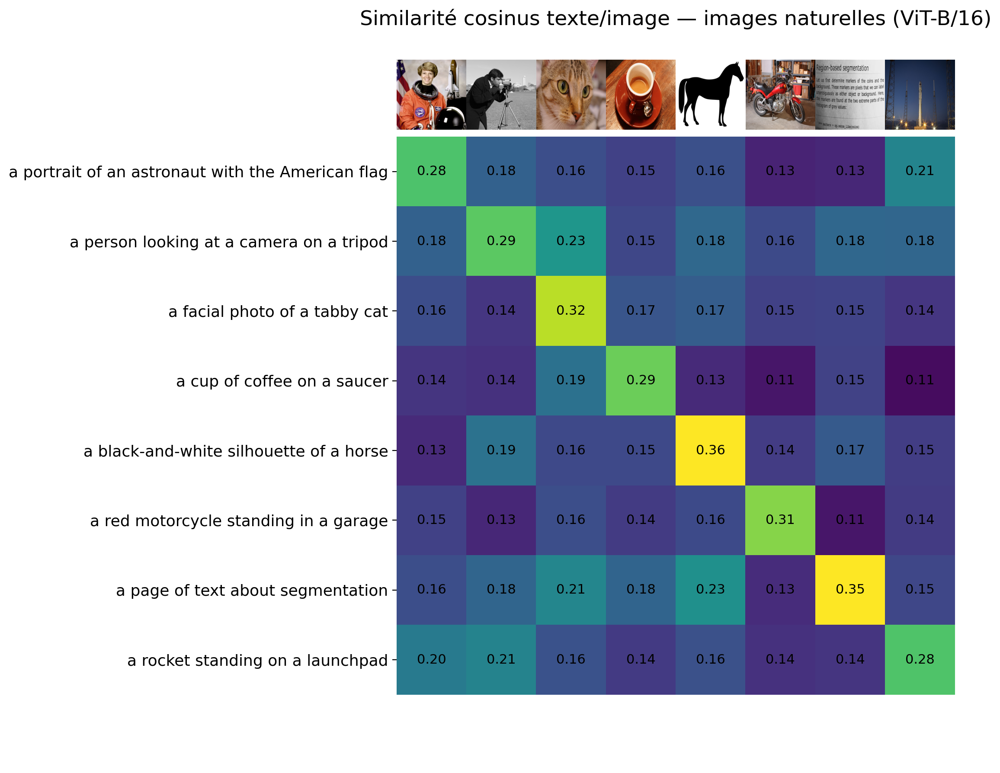

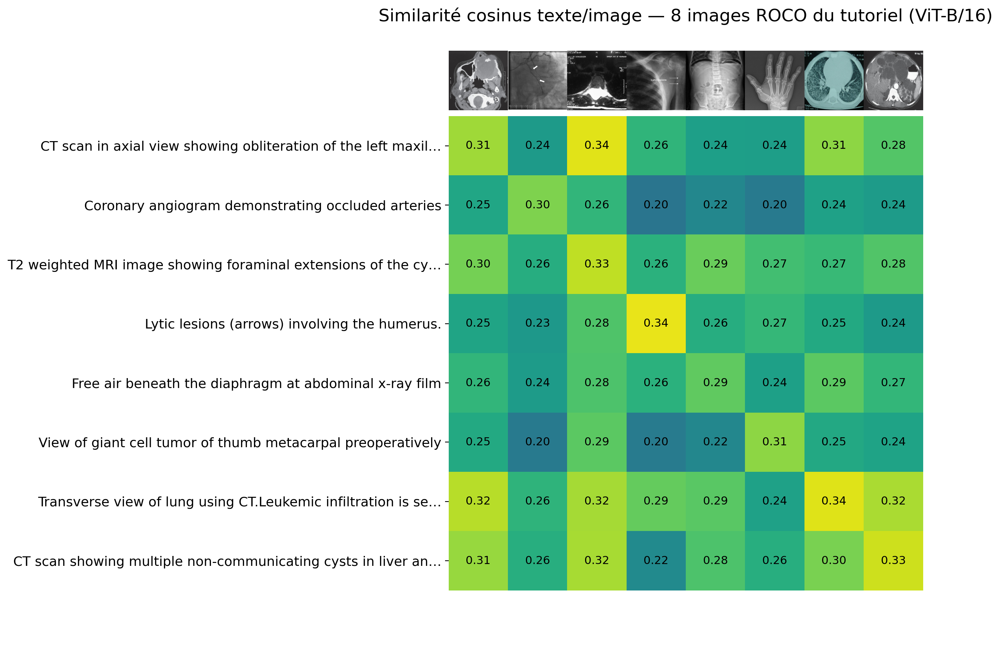

{
  "naturelles": {
    "n": 8,
    "acc_image_vers_texte": 8,
    "acc_texte_vers_image": 8,
    "sim_diag_moy": 0.3098888397216797,
    "sim_hors_diag_moy": 0.1592712700366974,
    "ecart": 0.1506175696849823
  },
  "medicales_tutoriel": {
    "n": 8,
    "acc_image_vers_texte": 5,
    "acc_texte_vers_image": 7,
    "sim_diag_moy": 0.3185935318470001,
    "sim_hors_diag_moy": 0.2624063193798065,
    "ecart": 0.056187212467193604
  }
}
Résultats sauvegardés dans /content/drive/MyDrive/TP_CLIP_resultats


In [34]:
import skimage

# Mêmes images et descriptions que dans le tutoriel
descriptions = {
    "page": "a page of text about segmentation",
    "chelsea": "a facial photo of a tabby cat",
    "astronaut": "a portrait of an astronaut with the American flag",
    "rocket": "a rocket standing on a launchpad",
    "motorcycle_right": "a red motorcycle standing in a garage",
    "camera": "a person looking at a camera on a tripod",
    "horse": "a black-and-white silhouette of a horse",
    "coffee": "a cup of coffee on a saucer",
}
med_descriptions = {
    "ROCO_00002": "CT scan in axial view showing obliteration of the left maxillary sinus",
    "ROCO_00017": "Coronary angiogram demonstrating occluded arteries",
    "ROCO_00028": "T2 weighted MRI image showing foraminal extensions of the cysts",
    "ROCO_00033": "Lytic lesions (arrows) involving the humerus.",
    "ROCO_00050": "Free air beneath the diaphragm at abdominal x-ray film",
    "ROCO_00056": "View of giant cell tumor of thumb metacarpal preoperatively",
    "ROCO_00060": "Transverse view of lung using CT.Leukemic infiltration is seen.",
    "ROCO_00135": "CT scan showing multiple non-communicating cysts in liver and kidney",
}

def similarity_matrix(model, preprocess, pil_images, texts, prefix="This is "):
    # Matrice [texte, image] de similarités cosinus, comme dans le tutoriel.
    with torch.no_grad():
        x = torch.stack([preprocess(im) for im in pil_images]).to(device)
        fi = model.encode_image(x).float(); fi /= fi.norm(dim=-1, keepdim=True)
    ft = encode_texts(model, [prefix + t for t in texts])
    return (ft @ fi.cpu().T).numpy()

def matching_stats(sim):
    # Indicateurs simples sur une matrice carrée texte x image dont la diagonale est la vérité terrain.
    n = sim.shape[0]
    diag = np.diag(sim)
    off = sim[~np.eye(n, dtype=bool)]
    return {"n": n,
            "acc_image_vers_texte": int((sim.argmax(axis=0) == np.arange(n)).sum()),
            "acc_texte_vers_image": int((sim.argmax(axis=1) == np.arange(n)).sum()),
            "sim_diag_moy": float(diag.mean()), "sim_hors_diag_moy": float(off.mean()),
            "ecart": float(diag.mean() - off.mean())}

def plot_similarity(sim, pil_images, texts, title, max_chars=60):
    # Reprise de la figure du tutoriel (images en haut, légendes à gauche).
    n = len(texts)
    plt.figure(figsize=(18, 11))
    plt.imshow(sim, vmin=0.1, vmax=0.35)
    labels = [t if len(t) <= max_chars else t[:max_chars] + "…" for t in texts]
    plt.yticks(range(n), labels, fontsize=13); plt.xticks([])
    for i, im in enumerate(pil_images):
        plt.imshow(im, extent=(i - 0.5, i + 0.5, -1.6, -0.6), origin="lower")
    for x in range(n):
        for y in range(n):
            plt.text(x, y, f"{sim[y, x]:.2f}", ha="center", va="center", size=11)
    for side in ["left", "top", "right", "bottom"]:
        plt.gca().spines[side].set_visible(False)
    plt.xlim([-0.5, n - 0.5]); plt.ylim([n + 0.5, -2])
    plt.title(title, size=17)

# --- Démo 1 : images naturelles ---
skimage.data.download_all(directory=None)
nat_images, nat_texts = [], []
for fname in sorted(os.listdir(skimage.data_dir)):
    name = os.path.splitext(fname)[0]
    if name in descriptions and fname.endswith((".png", ".jpg")):
        nat_images.append(Image.open(os.path.join(skimage.data_dir, fname)).convert("RGB"))
        nat_texts.append(descriptions[name])
sim_nat = similarity_matrix(model, preprocess, nat_images, nat_texts)
plot_similarity(sim_nat, nat_images, nat_texts, "Similarité cosinus texte/image — images naturelles (ViT-B/16)")
save_fig("q1_similarite_naturelles.png"); plt.show()

# --- Démo 2 : les 8 images médicales du tutoriel ---
med_images = [Image.open(os.path.join(ROCO_TRAIN_DIR, k + ".jpg")).convert("RGB") for k in med_descriptions]
med_texts = list(med_descriptions.values())
sim_med = similarity_matrix(model, preprocess, med_images, med_texts)
plot_similarity(sim_med, med_images, med_texts, "Similarité cosinus texte/image — 8 images ROCO du tutoriel (ViT-B/16)")
save_fig("q1_similarite_medicales.png"); plt.show()

results["q1"] = {"naturelles": matching_stats(sim_nat), "medicales_tutoriel": matching_stats(sim_med)}
print(json.dumps(results["q1"], indent=2)); save_results()

> **Commentaire (sortie).** Les deux figures reprennent celles du tutoriel. Les indicateurs confirment ce qu'on voyait à l'œil :
>
> | | Images naturelles | Images ROCO |
> |---|---|---|
> | Bonnes associations image → texte | 8/8 | 5/8 |
> | Bonnes associations texte → image | 8/8 | 7/8 |
> | Similarité moyenne bonnes paires | 0,310 | 0,319 |
> | Similarité moyenne mauvaises paires | 0,159 | 0,262 |
> | Écart | **0,151** | **0,056** |
>
> Les bonnes paires médicales ont une similarité aussi élevée que les naturelles. La différence vient des mauvaises paires, beaucoup plus similaires entre elles : CLIP place toutes les images radiologiques dans une même région de l'espace et les sépare mal.

## 2. Comparaison des modèles CLIP disponibles (consigne 2)

`clip.available_models()` donne 9 modèles qui diffèrent par leur **encodeur d'image** :
- 5 **ResNet** modifiés (RN50, RN101, et RN50x4/x16/x64, versions agrandies en largeur, profondeur et résolution, dans l'esprit d'EfficientNet) ;
- 4 **Vision Transformers** (Dosovitskiy et al., 2020, vus en cours) : B/32 et B/16 désignent un ViT-Base avec des patchs de 32 ou 16 pixels, L/14 un ViT-Large avec des patchs de 14 pixels, et `@336px` la même architecture affinée à une résolution de 336 pixels.

**Protocole.** Les mêmes données et le même prompt servent pour tous les modèles, afin que seul le modèle change :
1. **CIFAR-100 zero-shot** : split chargé par défaut par torchvision, c'est-à-dire les 50 000 images d'entraînement (sans `train=False`) ; CLIP n'ayant jamais été entraîné sur CIFAR, la mesure reste du zero-shot, prompt `"a photo of a {}."`, qui est le prompt de base de Radford et al. Métriques : top-1 et top-5.
2. **ROCO recherche image ↔ texte** : 1 000 paires du jeu de test ROCO. Pour chaque image, on classe les 1 000 légendes, et inversement. Métrique : Recall@K (cours, partie *Evaluation*).
3. **Coût** : nombre de paramètres et temps d'encodage moyen par image sur le GPU de Colab.

*Remarque : les plus gros modèles (RN50x64 et ViT-L/14 en 336 pixels) prennent plusieurs minutes chacun. Si la session Colab est limitée, retirer des modèles de `MODELS`.*

In [35]:
from torchvision.datasets import CIFAR100

class ROCOPairs(Dataset):
    # Paires (image, légende) ROCO lues depuis le CSV (colonne 0 = nom du fichier, colonne 1 = légende).
    # Version simplifiée de la classe CLRDataset du tutoriel : on renvoie l'indice de la paire
    # au lieu du texte, pour retrouver la légende correspondante lors de l'évaluation.
    def __init__(self, csv_file, root_dir, n=None, transform=None, seed=SEED):
        # Correction automatique du dossier de test s'il est vide/inexistant
        if not os.path.exists(root_dir) or len(os.listdir(root_dir)) == 0:
            fallback_dir = root_dir.replace("test", "val").replace("train", "val")
            if os.path.exists(fallback_dir) and len(os.listdir(fallback_dir)) > 0:
                root_dir = fallback_dir
            else:
                root_dir = root_dir.replace("test", "train").replace("val", "train")

        df = pd.read_csv(csv_file)
        df = df.rename(columns={df.columns[0]: "name", df.columns[1]: "caption"})
        df = df.dropna(subset=["caption"])
        df["caption"] = df["caption"].astype(str).str.replace("\n", " ").str.strip()
        df["path"] = [os.path.join(root_dir, f) for f in df["name"]]
        df = df[[os.path.exists(p) for p in df["path"]]]          # on ignore les images absentes
        if n is not None and n < len(df):
            df = df.sample(n=n, random_state=seed)                  # échantillon fixe et reproductible
        self.df = df.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        image = Image.open(self.df.loc[idx, "path"]).convert("RGB")
        return self.transform(image), idx

roco_pairs = ROCOPairs(ROCO_TEST_CSV, ROCO_TEST_DIR, n=N_ROCO_RETRIEVAL)
roco_captions = roco_pairs.df["caption"].tolist()
print("Paires ROCO utilisées :", len(roco_pairs))
if len(roco_captions) > 0:
    print("Exemple de légende :", roco_captions[0])
else:
    print("⚠ Aucune paire trouvée. Vérifiez vos chemins d'accès aux images.")

Paires ROCO utilisées : 1000
Exemple de légende : Cerebral angiogram, showing a delayed posttraumatic aneurysm that involves the hypophyseal artery (arrow).


> **Commentaire (sortie).** 1 000 paires sont tirées au hasard (graine fixée) parmi les paires de validation dont l'image existe. Pour chaque image, la bonne légende est donc à trouver parmi 1 000. On note R@K (Recall@K) la part des requêtes dont la bonne réponse est dans les K premiers résultats : R@1 compte les réponses exactes du premier coup, R@10 celles qui sont dans le top 10. Un tirage au hasard donnerait R@1 = 0,1 % et R@10 = 1 %.

In [38]:
def evaluate_roco_retrieval(model, preprocess):
    # Recherche image -> texte et texte -> image sur les paires ROCO.
    roco_pairs.transform = preprocess        # chaque modèle a sa propre résolution d'entrée
    loader = DataLoader(roco_pairs, batch_size=BATCH_SIZE, num_workers=NUM_WORKERS)
    img_f, idx, _ = encode_images(model, loader)
    txt_f = encode_texts(model, [roco_captions[i] for i in idx.tolist()])
    sim = img_f @ txt_f.T                    # [image, texte]
    i2t = recall_at_k(sim)
    t2i = recall_at_k(sim.T)
    return {**{f"i2t_{k}": v for k, v in i2t.items()}, **{f"t2i_{k}": v for k, v in t2i.items()}}


MODELS = clip.available_models()   # les 9 modèles
TEMPLATE = "a photo of a {}."
q2 = []
for name in MODELS:
    print(f"\n===== {name} =====")
    m, prep = clip.load(name, device=device); m.eval()

    # 1) CIFAR-100 zero-shot. Remarque : sans train=False, torchvision charge le split
    #    d'entraînement (50 000 images) et non le test (10 000 images).
    # Correction : Utilisation de prep (spécifique au modèle) au lieu de la variable globale preprocess
    cifar = CIFAR100(root="/content/sample_data", transform=prep, download=False)
    loader = DataLoader(cifar, batch_size=BATCH_SIZE, num_workers=NUM_WORKERS)
    img_f, labels, ms = encode_images(m, loader)
    txt_f = zero_shot_classifier(m, cifar.classes, TEMPLATE)
    acc, _ = topk_accuracy(img_f, txt_f, labels)

    # 2) ROCO recherche image <-> texte
    roco = evaluate_roco_retrieval(m, prep)

    row = {"modele": name, "params_M": count_params(m) / 1e6,
           "resolution": m.visual.input_resolution, "dim_embedding": m.text_projection.shape[1],
           "ms_par_image": ms,
           "cifar100_top1": acc["top1"], "cifar100_top5": acc["top5"], **roco}
    print(row)
    q2.append(row)
    results["q2"] = q2; save_results()

    del m; torch.cuda.empty_cache()

df_q2 = pd.DataFrame(q2).round(2)
df_q2


===== RN50 =====


/usr/local/lib/python3.13/dist-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


{'modele': 'RN50', 'params_M': 102.007137, 'resolution': 224, 'dim_embedding': 1024, 'ms_par_image': 2.1810097551345824, 'cifar100_top1': 40.498000383377075, 'cifar100_top5': 72.69600033760071, 'i2t_R@1': 4.500000178813934, 'i2t_R@5': 13.699999451637268, 'i2t_R@10': 20.800000429153442, 't2i_R@1': 4.100000113248825, 't2i_R@5': 12.89999932050705, 't2i_R@10': 19.099999964237213}
Résultats sauvegardés dans /content/drive/MyDrive/TP_CLIP_resultats

===== RN101 =====
{'modele': 'RN101', 'params_M': 119.688033, 'resolution': 224, 'dim_embedding': 512, 'ms_par_image': 2.548774619102478, 'cifar100_top1': 46.92400097846985, 'cifar100_top5': 76.43799781799316, 'i2t_R@1': 4.399999976158142, 'i2t_R@5': 13.199999928474426, 'i2t_R@10': 20.70000022649765, 't2i_R@1': 4.899999871850014, 't2i_R@5': 13.79999965429306, 't2i_R@10': 21.0999995470047}
Résultats sauvegardés dans /content/drive/MyDrive/TP_CLIP_resultats

===== RN50x4 =====
{'modele': 'RN50x4', 'params_M': 178.300601, 'resolution': 288, 'dim_emb

100%|███████████████████████████████████████| 630M/630M [01:11<00:00, 9.27MiB/s]


{'modele': 'RN50x16', 'params_M': 290.979217, 'resolution': 384, 'dim_embedding': 768, 'ms_par_image': 13.443186292648315, 'cifar100_top1': 48.77200126647949, 'cifar100_top5': 75.81999897956848, 'i2t_R@1': 7.400000095367432, 'i2t_R@5': 18.799999356269836, 'i2t_R@10': 28.200000524520874, 't2i_R@1': 8.399999886751175, 't2i_R@5': 18.799999356269836, 't2i_R@10': 28.40000092983246}
Résultats sauvegardés dans /content/drive/MyDrive/TP_CLIP_resultats

===== RN50x64 =====


100%|██████████████████████████████████████| 1.26G/1.26G [00:07<00:00, 183MiB/s]


... (4 outputs left out)

{'modele': 'ViT-L/14', 'params_M': 427.616513, 'resolution': 224, 'dim_embedding': 768, 'ms_par_image': 12.033971996307374, 'cifar100_top1': 76.03200078010559, 'cifar100_top5': 93.42600107192993, 'i2t_R@1': 9.399999678134918, 'i2t_R@5': 24.400000274181366, 'i2t_R@10': 34.79999899864197, 't2i_R@1': 6.89999982714653, 't2i_R@5': 22.100000083446503, 't2i_R@10': 31.400001049041748}
Résultats sauvegardés dans /content/drive/MyDrive/TP_CLIP_resultats

===== ViT-L/14@336px =====


100%|███████████████████████████████████████| 891M/891M [00:27<00:00, 33.7MiB/s]


{'modele': 'ViT-L/14@336px', 'params_M': 427.944193, 'resolution': 336, 'dim_embedding': 768, 'ms_par_image': 29.007312850952147, 'cifar100_top1': 75.67800283432007, 'cifar100_top5': 93.25199723243713, 'i2t_R@1': 10.100000351667404, 'i2t_R@5': 24.19999986886978, 'i2t_R@10': 35.40000021457672, 't2i_R@1': 7.999999821186066, 't2i_R@5': 21.699999272823334, 't2i_R@10': 33.70000123977661}
Résultats sauvegardés dans /content/drive/MyDrive/TP_CLIP_resultats


,modele,params_M,resolution,dim_embedding,ms_par_image,cifar100_top1,cifar100_top5,i2t_R@1,i2t_R@5,i2t_R@10,t2i_R@1,t2i_R@5,t2i_R@10
0,RN50,102.01,224,1024,2.18,40.50,72.70,4.5,13.7,20.8,4.1,12.9,19.1
1,RN101,119.69,224,512,2.55,46.92,76.44,4.4,13.2,20.7,4.9,13.8,21.1
2,RN50x4,178.30,288,640,5.07,42.45,71.74,5.3,16.7,25.4,7.1,17.9,26.1
3,RN50x16,290.98,384,768,13.44,48.77,75.82,7.4,18.8,28.2,8.4,18.8,28.4
4,RN50x64,623.26,448,1024,38.46,55.72,81.11,8.9,22.5,33.6,8.4,22.8,31.6
5,ViT-B/32,151.28,224,512,2.05,62.33,86.93,4.7,15.2,21.8,3.6,12.5,19.0
6,ViT-B/16,149.62,224,512,3.14,67.17,89.09,7.1,18.6,26.9,5.8,15.3,25.1
7,ViT-L/14,427.62,224,768,12.03,76.03,93.43,9.4,24.4,34.8,6.9,22.1,31.4
8,ViT-L/14@336px,427.94,336,768,29.01,75.68,93.25,10.1,24.2,35.4,8.0,21.7,33.7


> **Commentaire (sortie).** Quelques constats sur ce tableau :
>
> - **CIFAR-100.** Les ViT dominent : à coût égal, ViT-B/32 (62,3 % top-1, 2,0 ms/image) fait 22 points de mieux que RN50 (40,5 %, 2,2 ms). Le meilleur est ViT-L/14 (76,0 %). La version 336 pixels de ViT-L/14 (nom officiel `ViT-L/14@336px`) n'apporte rien (75,7 %) et coûte 2,4 fois plus de temps : les images CIFAR font 32×32 pixels, augmenter la résolution d'entrée n'ajoute pas d'information. RN50x4 fait moins bien que RN101 (42,5 % contre 46,9 %) malgré plus de paramètres.
> - **Comparaison avec l'article.** Radford et al. (2021, tableau 11) donnent 41,6 % pour RN50, 68,7 % pour ViT-B/16 et 77,9 % pour ViT-L/14. Nos chiffres sont 1 à 2 points plus bas. Deux différences peuvent l'expliquer : nous utilisons un seul prompt (l'article combine plusieurs prompts) et le split d'entraînement de CIFAR-100 au lieu du test.
> - **ROCO.** Tous les modèles restent faibles (R@1 entre 4 et 10 %), même si c'est 40 à 100 fois mieux que le hasard. Le classement change par rapport à CIFAR : RN50x16 (R@10 = 28,2 %) et RN50x64 (33,6 %) battent ViT-B/16 (26,9 %), alors qu'ils sont loin derrière sur CIFAR. Ces ResNet travaillent en 384 et 448 pixels ; on peut supposer que la résolution aide à voir les détails fins des images radiologiques. Les deux ViT-L restent les meilleurs (R@10 ≈ 35 %).
> - **Coût.** Le temps d'encodage va de 2 ms (ViT-B/32) à 38 ms (RN50x64) par image sur le GPU T4 de Colab.

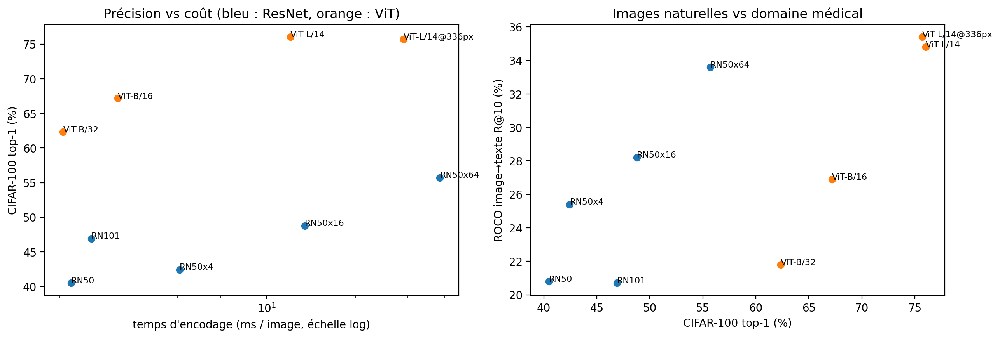

In [39]:
# Visualisation : compromis précision / coût de calcul
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for _, r in df_q2.iterrows():
    color = "tab:blue" if r["modele"].startswith("RN") else "tab:orange"
    ax[0].scatter(r["ms_par_image"], r["cifar100_top1"], c=color)
    ax[0].annotate(r["modele"], (r["ms_par_image"], r["cifar100_top1"]), fontsize=8)
    ax[1].scatter(r["cifar100_top1"], r["i2t_R@10"], c=color)
    ax[1].annotate(r["modele"], (r["cifar100_top1"], r["i2t_R@10"]), fontsize=8)
ax[0].set_xscale("log"); ax[0].set_xlabel("temps d'encodage (ms / image, échelle log)")
ax[0].set_ylabel("CIFAR-100 top-1 (%)"); ax[0].set_title("Précision vs coût (bleu : ResNet, orange : ViT)")
ax[1].set_xlabel("CIFAR-100 top-1 (%)"); ax[1].set_ylabel("ROCO image→texte R@10 (%)")
ax[1].set_title("Images naturelles vs domaine médical")
plt.tight_layout(); save_fig("q2_comparaison_modeles.png"); plt.show()

> **Commentaire (sortie).** À gauche, les ViT (orange) sont tous au-dessus des ResNet (bleu) pour un temps de calcul donné. À droite, les points ne sont pas alignés : un bon score sur CIFAR-100 ne garantit pas un bon score sur ROCO. ViT-B/32 et ViT-B/16 sont même en dessous de RN50x16 et RN50x64 sur ROCO.

## 3. CLIP dans le domaine médical : d'autres exemples ROCO (consigne 3)

ROCO (Pelka et al., 2018) contient des images de radiologie extraites d'articles PubMed Central, avec leur légende. CLIP n'a pas été entraîné spécifiquement sur ce type de données. On teste trois choses, avec ViT-B/16 **zero-shot**, puis avec le **checkpoint fine-tuné sur ROCO** fourni avec le TP s'il est trouvé :

1. **8 nouveaux exemples** tirés au hasard du jeu de test : même heatmap qu'en partie 1.
2. **Recherche image ↔ texte** sur 1 000 paires de test (Recall@K).
3. **Classification zero-shot de la modalité d'imagerie** (scanner, IRM, radiographie, échographie, angiographie). L'étiquette est extraite automatiquement de la légende par mots-clés, et on ne garde que les légendes qui citent une seule modalité. C'est une tâche plus « grossière » que la recherche de légende exacte, ce qui permet de voir si CLIP reconnaît au moins le type d'examen.

In [40]:
import glob

# --- Recherche du checkpoint fine-tuné (chemins du tutoriel + recherche dans le dossier partagé) ---
candidates = ["/content/drive/MyDrive/data/ViT-B-16_best_checkpoint_2.tar",   # chemin utilisé à la fin du tutoriel
              os.path.join(BASE_PATH, "ViT-B-16_best_checkpoint_2.tar"),
              "/content/drive/MyDrive/model_checkpoint_CLIP_ROCO/best_checkpoint.pth"]   # sortie du fine-tuning du tutoriel
candidates += glob.glob(os.path.join(BASE_PATH, "**", "*checkpoint*"), recursive=True)
CKPT_PATH = next((p for p in candidates if os.path.isfile(p)), None)
print("Checkpoint fine-tuné :", CKPT_PATH)

def load_finetuned(path):
    m, prep = clip.load("ViT-B/16", device=device, jit=False)
    state = torch.load(path, map_location=device)
    if isinstance(state, dict) and "state_dict" in state:
        state = state["state_dict"]
    m.load_state_dict(state)
    return m.eval(), prep

models_q3 = {"zero_shot": (model, preprocess)}          # ViT-B/16 chargé en partie 1
if CKPT_PATH is not None:
    models_q3["fine_tune_ROCO"] = load_finetuned(CKPT_PATH)

Checkpoint fine-tuné : /content/drive/MyDrive/dataset_roco/data/ViT-B-16_best_checkpoint_2.tar


/usr/local/lib/python3.13/dist-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


> **Commentaire (sortie).** Le checkpoint fine-tuné fourni avec les données est trouvé dans `dataset_roco/data`. La partie 3 compare donc ViT-B/16 zero-shot et ViT-B/16 fine-tuné sur ROCO, avec exactement les mêmes images de validation.

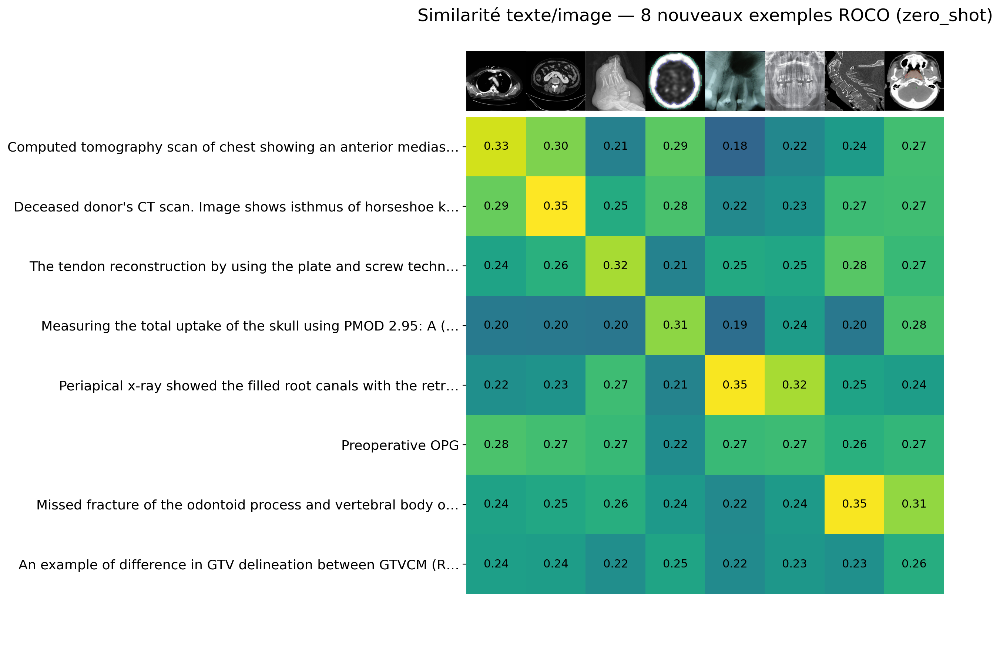

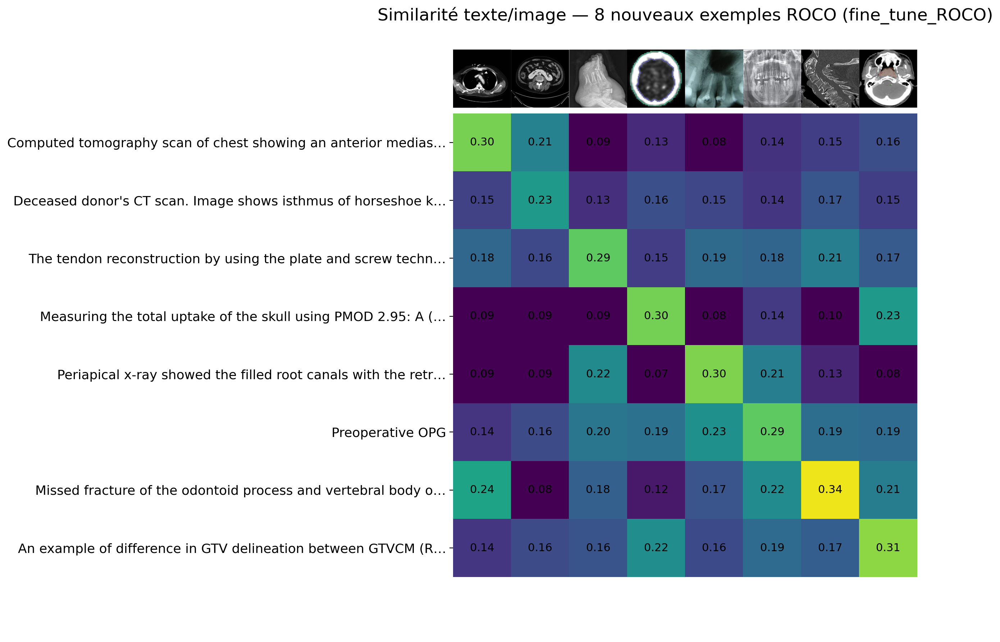

{
  "zero_shot": {
    "i2t_R@1": 7.100000232458115,
    "i2t_R@5": 18.60000044107437,
    "i2t_R@10": 26.899999380111694,
    "t2i_R@1": 5.799999833106995,
    "t2i_R@5": 15.299999713897705,
    "t2i_R@10": 25.099998712539673
  },
  "fine_tune_ROCO": {
    "i2t_R@1": 27.59999930858612,
    "i2t_R@5": 56.199997663497925,
    "i2t_R@10": 69.40000057220459,
    "t2i_R@1": 26.399999856948853,
    "t2i_R@5": 56.99999928474426,
    "t2i_R@10": 69.80000138282776
  }
}
Résultats sauvegardés dans /content/drive/MyDrive/TP_CLIP_resultats


In [41]:
# --- 3.1 Huit nouveaux exemples tirés au hasard dans le jeu de test ROCO ---
ex = roco_pairs.df.sample(n=8, random_state=0)
ex_images = [Image.open(p).convert("RGB") for p in ex["path"]]
ex_texts = ex["caption"].tolist()

results["q3"] = {"exemples": {"noms": ex["name"].tolist(), "legendes": ex_texts}}
for tag, (m, prep) in models_q3.items():
    sim = similarity_matrix(m, prep, ex_images, ex_texts)
    plot_similarity(sim, ex_images, ex_texts, f"Similarité texte/image — 8 nouveaux exemples ROCO ({tag})")
    save_fig(f"q3_exemples_{tag}.png"); plt.show()
    results["q3"]["exemples"][tag] = matching_stats(sim)

# --- 3.2 Recherche image <-> texte sur 1 000 paires ---
results["q3"]["recherche"] = {tag: evaluate_roco_retrieval(m, prep) for tag, (m, prep) in models_q3.items()}
print(json.dumps(results["q3"]["recherche"], indent=2)); save_results()

> **Commentaire (sortie).** Sur les 8 nouvelles images de validation, le modèle zero-shot obtient (lecture de la heatmap) environ 7 bonnes associations sur 8 dans le sens texte → image et 6 sur 8 dans l'autre sens. Les erreurs concernent les deux images dentaires (radiographie périapicale et panoramique « OPG »), confondues entre elles, et le dernier scanner, rapproché de la légende sur la fracture de l'odontoïde. La légende très courte « Preoperative OPG » a des similarités entre 0,22 et 0,28 avec toutes les images : CLIP ne semble pas connaître l'abréviation OPG. Après fine-tuning, les 8 associations sont correctes dans les deux sens et les mauvaises paires descendent vers 0,1.
>
> Sur les 1 000 paires, le fine-tuning multiplie R@1 par environ 4 (7,1 % → 27,6 % en image → texte) et R@10 passe de 26,9 % à 69,4 %. Réserve : le checkpoint s'appelle « best », il a probablement été choisi sur la loss de validation, calculée sur ce même fichier `local-val-list.csv`. Le gain réel sur des données jamais vues pourrait donc être un peu plus faible.

Images retenues : 626 | répartition : {'CT': 231, 'MRI': 118, 'X-ray': 164, 'ultrasound': 74, 'angiography': 39}


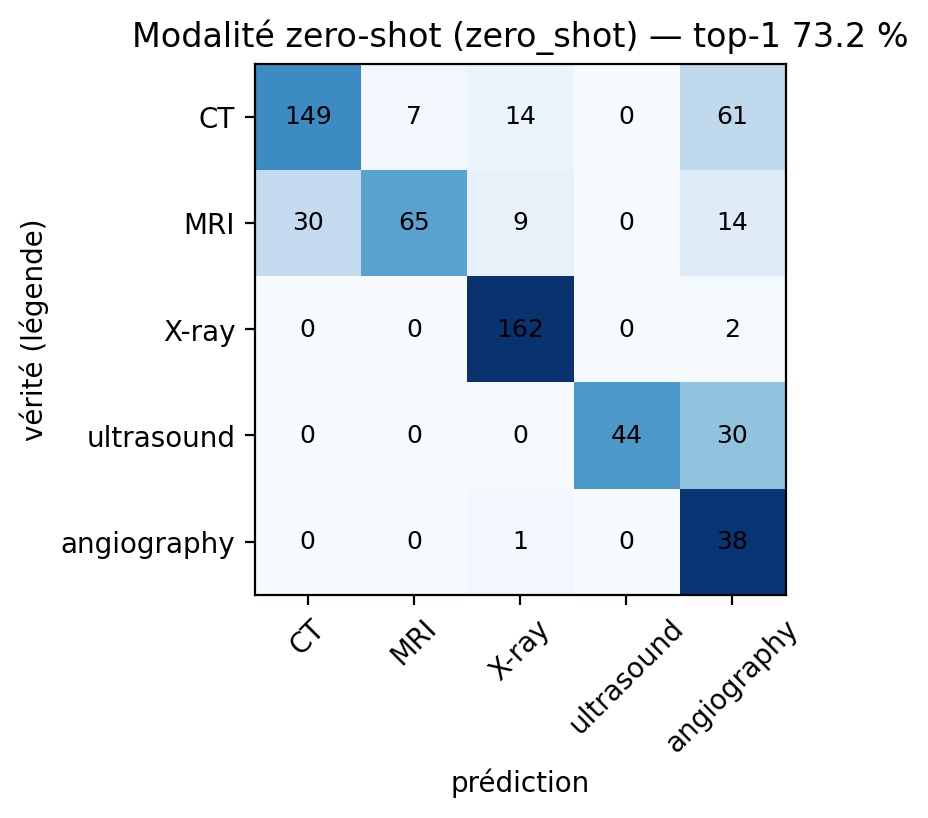

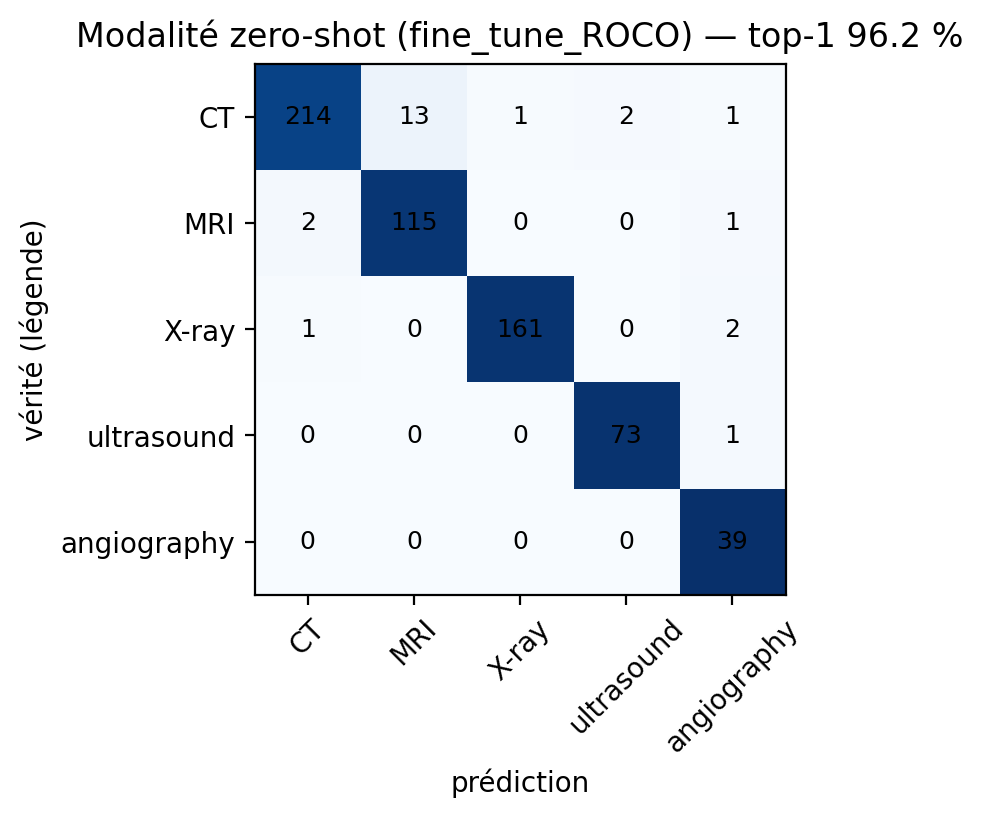

{
  "n": 626,
  "repartition": {
    "CT": 231,
    "MRI": 118,
    "X-ray": 164,
    "ultrasound": 74,
    "angiography": 39
  },
  "zero_shot": {
    "top1": 73.16293716430664,
    "moyenne_par_classe": 75.05255103111267,
    "confusion": [
      [
        149,
        7,
        14,
        0,
        61
      ],
      [
        30,
        65,
        9,
        0,
        14
      ],
      [
        0,
        0,
        162,
        0,
        2
      ],
      [
        0,
        0,
        0,
        44,
        30
      ],
      [
        0,
        0,
        1,
        0,
        38
      ]
    ]
  },
  "fine_tune_ROCO": {
    "top1": 96.16613388061523,
    "moyenne_par_classe": 97.38354086875916,
    "confusion": [
      [
        214,
        13,
        1,
        2,
        1
      ],
      [
        2,
        115,
        0,
        0,
        1
      ],
      [
        1,
        0,
        161,
        0,
        2
      ],
      [
        0,
        0,
        0,
  

In [42]:
# --- 3.3 Classification zero-shot de la modalité d'imagerie ---
# Étiquettes extraites de la légende par expressions régulières (une seule modalité citée)
MODALITY_PATTERNS = {
    "CT":           r"\bct\b|computed tomograph",
    "MRI":          r"\bmri\b|\bmr\b|magnetic resonance|t[12][- ]weighted",
    "X-ray":        r"x-ray|\bradiograph|plain film",
    "ultrasound":   r"ultrasound|ultrasonograph|sonograph|echocardiogra|doppler",
    "angiography":  r"angiogra",
}
MODALITY_PROMPTS = {               # une phrase en langage naturel par classe
    "CT": "a CT scan",
    "MRI": "an MRI scan",
    "X-ray": "an X-ray radiograph",
    "ultrasound": "an ultrasound image",
    "angiography": "an angiography image",
}
classes = list(MODALITY_PATTERNS)

def caption_to_modality(caption):
    found = [c for c, pat in MODALITY_PATTERNS.items() if re.search(pat, caption.lower())]
    return classes.index(found[0]) if len(found) == 1 else -1   # -1 = ambigu ou absent

mod_labels = np.array([caption_to_modality(c) for c in roco_captions])
keep = np.where(mod_labels >= 0)[0]
counts = {c: int((mod_labels == i).sum()) for i, c in enumerate(classes)}
print("Images retenues :", len(keep), "| répartition :", counts)

from torch.utils.data import Subset
results["q3"]["modalite"] = {"n": int(len(keep)), "repartition": counts}
for tag, (m, prep) in models_q3.items():
    roco_pairs.transform = prep
    loader = DataLoader(Subset(roco_pairs, keep.tolist()), batch_size=BATCH_SIZE, num_workers=NUM_WORKERS)
    img_f, idx, _ = encode_images(m, loader)
    y = torch.as_tensor(mod_labels[idx.numpy()])
    txt_f = zero_shot_classifier(m, [MODALITY_PROMPTS[c] for c in classes], "{}")
    acc, preds = topk_accuracy(img_f, txt_f, y, ks=(1,))

    # matrice de confusion (lignes = vraie modalité, colonnes = prédiction)
    conf = np.zeros((len(classes), len(classes)), dtype=int)
    for t, p in zip(y.tolist(), preds.tolist()):
        conf[t, p] += 1
    results["q3"]["modalite"][tag] = {
        "top1": acc["top1"],
        "moyenne_par_classe": mean_per_class_accuracy(preds, y, len(classes)),
        "confusion": conf.tolist()}

    plt.figure(figsize=(5, 4.2))
    plt.imshow(conf / conf.sum(axis=1, keepdims=True).clip(min=1), cmap="Blues", vmin=0, vmax=1)
    plt.xticks(range(len(classes)), classes, rotation=45); plt.yticks(range(len(classes)), classes)
    for i in range(len(classes)):
        for j in range(len(classes)):
            plt.text(j, i, conf[i, j], ha="center", va="center", fontsize=9)
    plt.xlabel("prédiction"); plt.ylabel("vérité (légende)")
    plt.title(f"Modalité zero-shot ({tag}) — top-1 {acc['top1']:.1f} %")
    plt.tight_layout(); save_fig(f"q3_modalite_{tag}.png"); plt.show()

print(json.dumps(results["q3"]["modalite"], indent=2)); save_results()

> **Commentaire (sortie).** 626 images sur 1 000 ont une légende qui cite une seule modalité (231 CT, 118 IRM, 164 radiographies, 74 échographies, 39 angiographies). Prédire toujours « CT » donnerait 36,9 %.
>
> - **Zero-shot : 73,2 % (moyenne par classe 75,1 %).** Les radiographies sont presque toutes reconnues (162/164). Les erreurs vont surtout vers « angiography » : 61 scanners sur 231 et 30 échographies sur 74 y sont classés. 30 IRM sur 118 sont prises pour des scanners, ce qui se comprend : ce sont deux coupes en niveaux de gris.
> - **Fine-tuné : 96,2 % (moyenne par classe 97,4 %).** La classe « angiography » n'attire plus les erreurs ; la confusion restante principale est CT → IRM (13 cas).
>
> Les étiquettes sont extraites automatiquement par mots-clés, elles contiennent donc un peu de bruit. Le résultat montre que CLIP zero-shot reconnaît assez bien le *type d'examen* alors qu'il retrouve mal la *légende exacte* (R@1 de 7 %).

## 4. Classification zero-shot sur un autre jeu : Oxford-IIIT Pet (consigne 4)

**Choix du jeu de données.** Oxford-IIIT Pet (Parkhi et al., 2012) contient 37 races de chats et de chiens, avec 3 669 images de test. On l'a choisi pour trois raisons :
- il est très différent de CIFAR-100 : images en haute résolution et classification **fine** (distinguer des races proches plutôt que des objets très différents) ;
- il fait partie des 27 jeux évalués par Radford et al. (2021), ce qui donne un point de comparaison pour vérifier nos chiffres ;
- il est disponible directement dans `torchvision` et pèse moins de 1 Go, ce qui convient à Colab.

**Protocole.** Quatre modèles (deux ResNet, deux ViT) et deux prompts :
- (A) `"a photo of a {}."` : le prompt générique de la partie 2 ;
- (B) `"a photo of a {}, a type of pet."` : prompt avec contexte, proposé par Radford et al. pour ce jeu. Il lève l'ambiguïté de certains noms de classes (« Boxer » peut aussi désigner un sportif).

Métriques : top-1, top-5 et précision moyenne par classe (métrique officielle de ce jeu dans l'article CLIP).

In [43]:
from torchvision.datasets import OxfordIIITPet

PETS_MODELS = ["RN50", "RN101", "ViT-B/32", "ViT-B/16"]
PROMPTS = {"A_generique": "a photo of a {}.",
           "B_contexte":  "a photo of a {}, a type of pet."}

q4 = []
for name in PETS_MODELS:
    m, prep = clip.load(name, device=device); m.eval()
    pets = OxfordIIITPet(os.path.expanduser("~/.cache"), split="test",
                         target_types="category", transform=prep, download=True)
    loader = DataLoader(pets, batch_size=BATCH_SIZE, num_workers=NUM_WORKERS)
    img_f, labels, _ = encode_images(m, loader)
    for p_name, template in PROMPTS.items():
        txt_f = zero_shot_classifier(m, pets.classes, template)
        acc, preds = topk_accuracy(img_f, txt_f, labels)
        row = {"modele": name, "prompt": p_name, **acc,
               "moyenne_par_classe": mean_per_class_accuracy(preds, labels, len(pets.classes))}
        print(row); q4.append(row)
        if name == "ViT-B/16" and p_name == "B_contexte":
            best = (img_f, txt_f, labels, preds)       # gardé pour l'analyse des erreurs
    results["q4"] = q4; save_results()
    del m; torch.cuda.empty_cache()

pd.DataFrame(q4).round(2)

/usr/local/lib/python3.13/dist-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(
100%|██████████| 792M/792M [00:35<00:00, 22.0MB/s]
100%|██████████| 19.2M/19.2M [00:01<00:00, 10.1MB/s]


{'modele': 'RN50', 'prompt': 'A_generique', 'top1': 83.6740255355835, 'top5': 97.38348126411438, 'moyenne_par_classe': 83.36593395954853}
{'modele': 'RN50', 'prompt': 'B_contexte', 'top1': 85.74543595314026, 'top5': 99.23685193061829, 'moyenne_par_classe': 85.49357483515868}
Résultats sauvegardés dans /content/drive/MyDrive/TP_CLIP_resultats
{'modele': 'RN101', 'prompt': 'A_generique', 'top1': 84.92777347564697, 'top5': 97.3017156124115, 'moyenne_par_classe': 84.64343692805316}
{'modele': 'RN101', 'prompt': 'B_contexte', 'top1': 86.91741824150085, 'top5': 99.04606342315674, 'moyenne_par_classe': 86.64243599853}
Résultats sauvegardés dans /content/drive/MyDrive/TP_CLIP_resultats
{'modele': 'ViT-B/32', 'prompt': 'A_generique', 'top1': 85.03679633140564, 'top5': 97.35623002052307, 'moyenne_par_classe': 84.69170718579679}
{'modele': 'ViT-B/32', 'prompt': 'B_contexte', 'top1': 87.43526935577393, 'top5': 99.2641031742096, 'moyenne_par_classe': 87.13683220180305}
Résultats sauvegardés dans /c

,modele,prompt,top1,top5,moyenne_par_classe
0,RN50,A_generique,83.67,97.38,83.37
1,RN50,B_contexte,85.75,99.24,85.49
2,RN101,A_generique,84.93,97.30,84.64
3,RN101,B_contexte,86.92,99.05,86.64
4,ViT-B/32,A_generique,85.04,97.36,84.69
5,ViT-B/32,B_contexte,87.44,99.26,87.14
6,ViT-B/16,A_generique,88.28,97.47,88.02
7,ViT-B/16,B_contexte,89.07,99.54,88.88


> **Commentaire (sortie).** Sur Oxford-IIIT Pet (3 669 images de test, 37 races), CLIP zero-shot fonctionne bien : de 83,7 % (RN50, prompt A) à 89,1 % top-1 (ViT-B/16, prompt B), et le top-5 dépasse 99 % avec le prompt B. Le prompt avec contexte « a type of pet » gagne de 0,8 à 2,4 points selon le modèle. Nos précisions moyennes par classe avec ce prompt sont très proches de l'article (tableau 11 de Radford et al., 2021) : 85,5 % contre 85,4 % pour RN50, 86,6 % contre 86,2 % pour RN101, 87,1 % contre 87,0 % pour ViT-B/32 et 88,9 % contre 88,9 % pour ViT-B/16. Cela valide le protocole d'évaluation.

Classes les plus difficiles : [('Bombay', 27.272728085517883), ('Birman', 46.00000083446503), ('American Pit Bull Terrier', 67.00000166893005), ('Persian', 72.00000286102295), ('Ragdoll', 72.00000286102295)]
Confusions les plus fréquentes : [('Birman -> Ragdoll', 45), ('American Pit Bull Terrier -> Staffordshire Bull Terrier', 22), ('Ragdoll -> Birman', 20), ('American Bulldog -> Boxer', 16), ('Egyptian Mau -> Bengal', 16)]
Résultats sauvegardés dans /content/drive/MyDrive/TP_CLIP_resultats


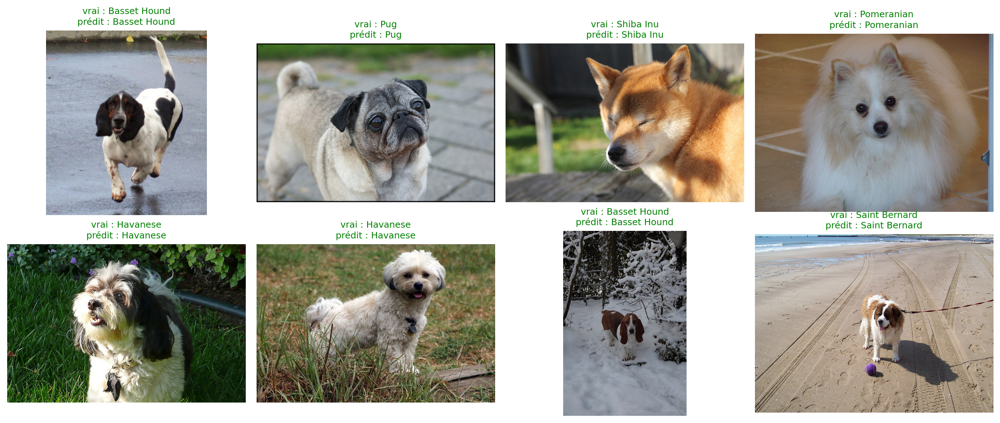

In [44]:
# Analyse des erreurs (ViT-B/16, prompt B) : classes les moins bien reconnues et confusions fréquentes
img_f, txt_f, labels, preds = best
n_cls = len(pets.classes)
per_class = {pets.classes[c]: 100.0 * (preds[labels == c] == c).float().mean().item() for c in range(n_cls)}
pires = sorted(per_class.items(), key=lambda kv: kv[1])[:5]

pairs = {}
for t, p in zip(labels.tolist(), preds.tolist()):
    if t != p:
        key = f"{pets.classes[t]} -> {pets.classes[p]}"
        pairs[key] = pairs.get(key, 0) + 1
confusions = sorted(pairs.items(), key=lambda kv: -kv[1])[:5]

results["q4_analyse"] = {"pires_classes": pires, "confusions_frequentes": confusions}
print("Classes les plus difficiles :", pires)
print("Confusions les plus fréquentes :", confusions)
save_results()

# Quelques prédictions illustrées (images brutes, sans prétraitement)
raw = OxfordIIITPet(os.path.expanduser("~/.cache"), split="test", target_types="category")
rng = np.random.default_rng(SEED)
plt.figure(figsize=(14, 6))
for k, i in enumerate(rng.choice(len(raw), 8, replace=False)):
    im, y = raw[i]
    plt.subplot(2, 4, k + 1); plt.imshow(im); plt.axis("off")
    ok = preds[i].item() == y
    plt.title(f"vrai : {raw.classes[y]}\nprédit : {raw.classes[preds[i]]}",
              fontsize=9, color="green" if ok else "red")
plt.tight_layout(); save_fig("q4_exemples_pets.png"); plt.show()

> **Commentaire (sortie).** Les erreurs se concentrent sur des races très proches visuellement. 45 Sacrés de Birmanie (Birman) sont classés Ragdoll et 20 Ragdoll sont classés Birman : ce sont deux chats à poils longs, colorpoint et aux yeux bleus. De même, 22 American Pit Bull Terrier sont pris pour des Staffordshire Bull Terrier. La pire classe est Bombay (27 % de réussite), un chat noir ; une hypothèse est que le mot « Bombay » renvoie surtout à la ville dans les textes du web, mais il faudrait le vérifier. Les 8 exemples tirés au hasard sont tous bien classés, ce qui est cohérent avec une précision de 89 %.

## Synthèse

1. **Prise en main.** CLIP aligne très bien images et textes naturels (écart bonnes/mauvaises paires de 0,151) mais beaucoup moins les paires ROCO (0,056). Deux points du tutoriel sont à connaître : la démo zero-shot applique les classes CIFAR-100 aux images médicales, et le fine-tuning s'arrête après une époque sans sauvegarder de checkpoint.
2. **Modèles.** Sur CIFAR-100, les ViT sont nettement meilleurs que les ResNet à coût égal (ViT-L/14 : 76,0 % top-1). Sur ROCO, le classement change et les ResNet haute résolution remontent ; aucun modèle ne dépasse 10 % de R@1.
3. **Médical.** Le fine-tuning sur ROCO multiplie le R@1 par 4 (7,1 % → 27,6 %). En zero-shot, CLIP reconnaît déjà la modalité d'imagerie dans 73 % des cas, 96 % après fine-tuning.
4. **Oxford-IIIT Pet.** 89,1 % top-1 en zero-shot avec ViT-B/16, des chiffres conformes à l'article ; les erreurs portent sur des races presque identiques.

**Références.** Radford et al. (2021), *Learning Transferable Visual Models From Natural Language Supervision*, ICML ; Pelka et al. (2018), *Radiology Objects in COntext (ROCO)*, MICCAI LABELS ; Parkhi et al. (2012), *Cats and Dogs*, CVPR ; Krizhevsky (2009), *Learning Multiple Layers of Features from Tiny Images* ; Dosovitskiy et al. (2021), *An Image is Worth 16x16 Words*, ICLR.
